# AI-Based Synthetic Insurance Data Generation and Claim Prediction

---

**Student Name:** Apeetha S.  
**Batch:** DSB02  
**Project Title:** AI-Based Synthetic Insurance Data Generation and Claim Prediction  
**Project Category:** Deep Learning / Basic GAN  
**Technique / Models:** CTGAN, Logistic Regression, Random Forest, XGBoost, Deep Neural Network  
**Submission Date:**  

---


## 1. Problem Definition

### 1.1 Problem Statement

Insurance companies use large volumes of policy and claims data for risk assessment and pricing. However, this data is often sensitive, and claims are rare events, which makes the data imbalanced and difficult to model. In the French motor third-party liability dataset used in this project (freMTPL2freq, about 678,000 policies), only about 5% of policies have a claim.

This project combines two tasks:

1. **Synthetic data generation:** a conditional tabular GAN (CTGAN) is trained on real policy data to generate synthetic insurance records, with a focus on claim records. The quality of the synthetic data is checked using a statistical quality score, feature distributions and correlations.
2. **Claim prediction:** policy and driver features are used to predict whether a policy will result in at least one claim (a binary classification task). Logistic Regression, Random Forest, XGBoost and a Deep Neural Network (DNN) are trained on real data only and on real data combined with synthetic claims, to examine whether the synthetic data improves prediction.

### 1.2 Project Objectives

* Analyze and understand the motor insurance dataset (freMTPL2freq).
* Perform data cleaning and preprocessing.
* Identify the numerical and categorical features related to insurance claims.
* Generate synthetic insurance data using a Conditional Tabular GAN (CTGAN).
* Evaluate the quality of the synthetic data by comparing it with the real data using a quality score, feature distributions and correlations.
* Prepare the data for machine learning and deep learning models.
* Handle the class imbalance (only about 5% of policies have a claim) using class weights and threshold tuning.
* Develop claim prediction models: Logistic Regression, Random Forest, XGBoost and a Deep Neural Network.
* Train each model on real data only and on real data combined with synthetic claims, and examine whether the synthetic data improves prediction.
* Evaluate and compare the models using F1 score, ROC-AUC and PR-AUC.

### 1.3 Target Users / Stakeholders

**Target Users:**

* **Insurance risk analysts and underwriting teams:** to identify policies with a higher chance of a claim when assessing risk and setting prices.
* **Claims management teams:** to understand which policy and driver profiles are more likely to lead to claims.
* **Data science and analytics teams:** to use synthetic data for developing and testing models without working directly on real customer records.

**Stakeholders:**

* **Insurance companies:** who benefit from better risk assessment.
* **Data protection and compliance teams:** who need to limit the use of sensitive customer data.
* **Policyholders (customers):** whose personal data is protected when synthetic data is used in place of real records.

### 1.4 Proposed AI Solution

The proposed solution consists of two major stages:

**Stage 1 – Synthetic Data Generation**

A Generative Adversarial Network (GAN) will be trained using the insurance dataset. The GAN consists of a **Generator** and a **Discriminator**. The Generator learns to create synthetic insurance records, while the Discriminator attempts to distinguish between real and generated records. Through adversarial training, the Generator learns to produce increasingly realistic synthetic data.

**Stage 2 – Insurance Claim Prediction**

The original and/or generated synthetic insurance data will be processed and used to develop classification models. Appropriate preprocessing techniques such as encoding, feature transformation, and scaling will be applied. Machine learning and deep learning models will then be trained to predict whether an insurance policy is likely to have a claim.

The performance of the models will be evaluated using appropriate classification metrics.

---



### 1.5 Input and Expected Output

**Input:**

The project uses insurance policy, vehicle, driver, geographical, and exposure-related information, including:

* Exposure
* Area
* Vehicle Power
* Vehicle Age
* Driver Age
* Bonus-Malus
* Vehicle Brand
* Vehicle Gas/Fuel Type
* Population Density
* Region

**Expected Outputs:**

The project produces two major outputs:

1. **Synthetic Insurance Data** generated by the GAN.
2. **Claim Prediction**, indicating whether an insurance policy is likely to have a claim.

For claim prediction:

* `0` → No Claim
* `1` → Claim

---



### 1.6 Project Category

**Category:** ML / DL / GAN

**Techniques Used:**

* Machine Learning
* Deep Learning
* Generative Adversarial Networks (GAN)
* Binary Classification
* Data Preprocessing
* Feature Engineering

---



# 2. Dataset Selection & Understanding

## 2.1 Dataset Source

**Dataset:** `freMTPL2freq`

The project uses the French Motor Third-Party Liability (MTPL) insurance frequency dataset, which contains policy-level information related to motor insurance.

The dataset provides information about policy exposure, vehicle characteristics, driver characteristics, geographical information, and insurance claims.

---



## 2.2 Dataset Description

The `freMTPL2freq` dataset contains motor insurance policy records that can be used to study claim occurrence and insurance risk.

**Dataset size:**

* **Rows:** 678,013
* **Columns:** 13

The dataset contains both numerical and categorical variables. It includes information about the insured vehicle, driver, geographical region, exposure period, and number of claims.

For this project, the claim information is transformed into a binary target variable, `HasClaim`, representing whether the policy has at least one claim.

---



## 2.3 Dataset Overview

The dataset was initially inspected to understand its structure, dimensions, data types, statistical characteristics, and data quality.

The main variables available in the dataset include:

* Policy identifier
* Number of claims
* Policy exposure
* Geographic area
* Vehicle power
* Vehicle age
* Driver age
* Bonus-Malus
* Vehicle brand
* Vehicle fuel type
* Population density
* Region
* Claim indicator

The initial data-quality analysis showed that the dataset contains **678,013 records and 13 columns**, with no missing values identified in the initial missing-value check.

---



## 2.4 Feature Description

| Feature | Description |
|---|---|
| `IDpol` | Unique identifier for the insurance policy |
| `ClaimNb` | Number of claims associated with the policy |
| `Exposure` | Exposure period of the insurance policy |
| `Area` | Geographic area associated with the policy |
| `VehPower` | Power of the insured vehicle |
| `VehAge` | Age of the insured vehicle |
| `DrivAge` | Age of the driver |
| `BonusMalus` | Bonus-malus insurance rating |
| `VehBrand` | Brand of the insured vehicle |
| `VehGas` | Fuel type of the vehicle |
| `Density` | Population density associated with the policy |
| `Region` | Geographic region |
| `HasClaim` | Binary indicator showing whether the policy has at least one claim |

---



## 2.5 Target Variable

### `HasClaim`

`HasClaim` is the target variable used for the insurance claim prediction component.

It is derived from the number of claims associated with each policy:

* **0 → No claim**
* **1 → At least one claim**

The objective of the classification component is to learn the relationship between the available policy characteristics and the occurrence of an insurance claim.

---



## 2.6 Dataset Suitability for the Project

The `freMTPL2freq` dataset is suitable for this project because it contains a large number of insurance policy records with a combination of numerical and categorical features.

The dataset can therefore support:

* **GAN-based synthetic data generation**, by learning the underlying patterns in insurance records.
* **Machine learning classification**, by predicting claim occurrence.
* **Deep learning approaches**, for learning complex relationships between insurance features and claim outcomes.
* **Comparative analysis**, between real and synthetically generated insurance data.

---

## **3. Exploratory Data Analysis**

### **3.1 Import Libraries**

---

In [32]:
!pip install liac-arff sdv xgboost -q

# name of the dataset file
DATA_FILE = "freMTPL2freq (1).arff"


[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [33]:
# Import libraries
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, roc_curve)
from xgboost import XGBClassifier


In [34]:
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

---

### **3.2 Load Dataset**
---

In [35]:
import arff

with open(DATA_FILE, "r") as f:
    data = arff.load(f)

df = pd.DataFrame(data["data"], columns=[attr[0] for attr in data["attributes"]])


---

### **3.3 Dataset Analysis**

---

In [36]:
# STEP 4: First look at the data
print("Shape (rows, columns):", df.shape)


Shape (rows, columns): (678013, 12)


In [37]:

print("\n--- First 5 rows ---")
display(df.head())


--- First 5 rows ---


,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
0,1.0,1.0,0.10,D,5.0,0.0,55.0,50.0,B12,Regular,1217.0,R82
1,3.0,1.0,0.77,D,5.0,0.0,55.0,50.0,B12,Regular,1217.0,R82
2,5.0,1.0,0.75,B,6.0,2.0,52.0,50.0,B12,Diesel,54.0,R22
3,10.0,1.0,0.09,B,7.0,0.0,46.0,50.0,B12,Diesel,76.0,R72
4,11.0,1.0,0.84,B,7.0,0.0,46.0,50.0,B12,Diesel,76.0,R72


In [38]:
print("\n--- Last 5 rows ---")
display(df.tail())


--- Last 5 rows ---


,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
678008,6114326.0,0.0,0.00274,E,4.0,0.0,54.0,50.0,B12,Regular,3317.0,R93
678009,6114327.0,0.0,0.00274,E,4.0,0.0,41.0,95.0,B12,Regular,9850.0,R11
678010,6114328.0,0.0,0.00274,D,6.0,2.0,45.0,50.0,B12,Diesel,1323.0,R82
678011,6114329.0,0.0,0.00274,B,4.0,0.0,60.0,50.0,B12,Regular,95.0,R26
678012,6114330.0,0.0,0.00274,B,7.0,6.0,29.0,54.0,B12,Diesel,65.0,R72


In [39]:
print("\n--- Column names ---")
print(df.columns.tolist())


--- Column names ---
['IDpol', 'ClaimNb', 'Exposure', 'Area', 'VehPower', 'VehAge', 'DrivAge', 'BonusMalus', 'VehBrand', 'VehGas', 'Density', 'Region']


In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 678013 entries, 0 to 678012
Data columns (total 12 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   IDpol       678013 non-null  float64
 1   ClaimNb     678013 non-null  float64
 2   Exposure    678013 non-null  float64
 3   Area        678013 non-null  object 
 4   VehPower    678013 non-null  float64
 5   VehAge      678013 non-null  float64
 6   DrivAge     678013 non-null  float64
 7   BonusMalus  678013 non-null  float64
 8   VehBrand    678013 non-null  object 
 9   VehGas      678013 non-null  object 
 10  Density     678013 non-null  float64
 11  Region      678013 non-null  object 
dtypes: float64(8), object(4)
memory usage: 62.1+ MB


In [41]:
print("\n--- Data types ---")
print(df.dtypes)


--- Data types ---
IDpol         float64
ClaimNb       float64
Exposure      float64
Area           object
VehPower      float64
VehAge        float64
DrivAge       float64
BonusMalus    float64
VehBrand       object
VehGas         object
Density       float64
Region         object
dtype: object


In [42]:
# Create the binary target for claim prediction

# 1 is for claimed and 0 is for not claimed.
df["HasClaim"] = (df["ClaimNb"] > 0).astype(int)

print("Shape after adding the target column:", df.shape)
print(f"Claim rate: {df['HasClaim'].mean():.2%}")

Shape after adding the target column: (678013, 13)
Claim rate: 5.02%


In [43]:
# Summary statistics
print("--- Numeric columns ---")
display(df.describe().T)

--- Numeric columns ---


,count,mean,std,min,25%,50%,75%,max
IDpol,678013.0,2.621857e+06,1.641783e+06,1.000000,1157951.00,2272152.00,4046274.00,6114330.00
ClaimNb,678013.0,5.324677e-02,2.401173e-01,0.000000,0.00,0.00,0.00,16.00
Exposure,678013.0,5.287501e-01,3.644415e-01,0.002732,0.18,0.49,0.99,2.01
VehPower,678013.0,6.454631e+00,2.050906e+00,4.000000,5.00,6.00,7.00,15.00
VehAge,678013.0,7.044265e+00,5.666232e+00,0.000000,2.00,6.00,11.00,100.00
DrivAge,678013.0,4.549912e+01,1.413744e+01,18.000000,34.00,44.00,55.00,100.00
BonusMalus,678013.0,5.976150e+01,1.563666e+01,50.000000,50.00,50.00,64.00,230.00
Density,678013.0,1.792422e+03,3.958647e+03,1.000000,92.00,393.00,1658.00,27000.00
HasClaim,678013.0,5.023502e-02,2.184297e-01,0.000000,0.00,0.00,0.00,1.00


In [44]:
print("\n--- Categorical columns ---")
display(df.describe(include=["object", "category"]).T)


--- Categorical columns ---


,count,unique,top,freq
Area,678013,6,C,191880
VehBrand,678013,11,B12,166024
VehGas,678013,2,Regular,345877
Region,678013,22,R24,160601


---

**Observation:**

Summary Statistics



---

In [45]:
# Separate numeric and categorical columns

id_and_target = ["IDpol", "ClaimNb", "HasClaim"]

num_cols = df.select_dtypes(include="number").columns.difference(id_and_target).tolist()
cat_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numeric features    :", num_cols)
print("Categorical features:", cat_cols)


Numeric features    : ['BonusMalus', 'Density', 'DrivAge', 'Exposure', 'VehAge', 'VehPower']
Categorical features: ['Area', 'VehBrand', 'VehGas', 'Region']


In [46]:
print("Categorical features and its number of unique values")
for c in cat_cols:
    print(f"{c}: {df[c].nunique()} unique values")

Categorical features and its number of unique values
Area: 6 unique values
VehBrand: 11 unique values
VehGas: 2 unique values
Region: 22 unique values


In [47]:
print("Categorical features and its unique values")
for c in cat_cols:
    print(f"{c}: {df[c].unique()}")

Categorical features and its unique values


Area: ['D' 'B' 'E' 'C' 'F' 'A']
VehBrand: ['B12' 'B6' 'B3' 'B2' 'B5' 'B10' 'B14' 'B13' 'B4' 'B1' 'B11']
VehGas: ['Regular' 'Diesel']
Region: ['R82' 'R22' 'R72' 'R31' 'R91' 'R52' 'R93' 'R11' 'R24' 'R94' 'R83' 'R54'
 'R26' 'R53' 'R73' 'R42' 'R25' 'R21' 'R41' 'R43' 'R74' 'R23']


---

### **3.4 Missing Value Analysis**

---

In [48]:
missing_values=df.isnull().sum()

print("\nTotal missing cells: ", missing_values )


Total missing cells:  IDpol         0
ClaimNb       0
Exposure      0
Area          0
VehPower      0
VehAge        0
DrivAge       0
BonusMalus    0
VehBrand      0
VehGas        0
Density       0
Region        0
HasClaim      0
dtype: int64


---

**Observation**

Missing Value Analysis

- The dataset has no missing values: every one of the 13 columns has a missing count of 0 (0.00%), and the total number of missing cells is 0.
- This agrees with the summary statistics, where every column had the same count of 678,013.
- No imputation is needed for this dataset.


---

### **3.5 Class Distribution**

---

In [49]:
# Class distribution of the target
counts = df["HasClaim"].value_counts()
pct = df["HasClaim"].value_counts(normalize=True) * 100

print(pd.DataFrame({"count": counts, "percent": pct.round(2)}))
print(f"Imbalance ratio (no claim : claim) = {counts[0] / counts[1]:.1f} : 1")


           count  percent
HasClaim                 
0         643953    94.98
1          34060     5.02
Imbalance ratio (no claim : claim) = 18.9 : 1


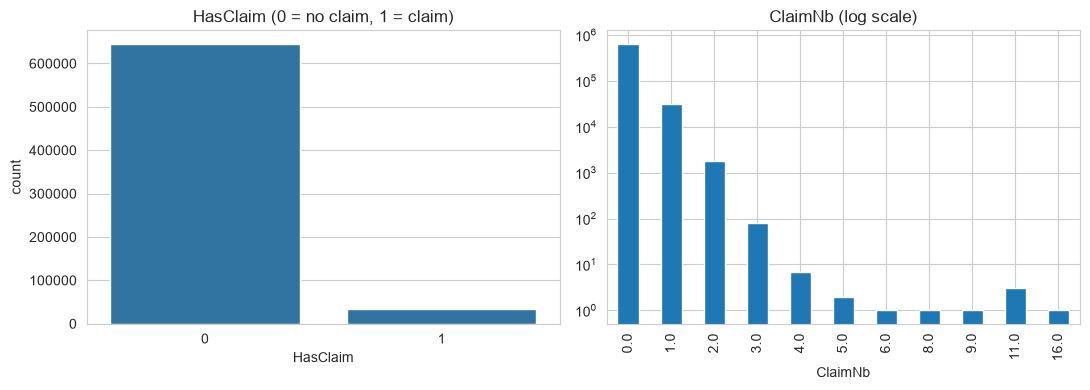

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="HasClaim", data=df, ax=axes[0])
axes[0].set_title("HasClaim (0 = no claim, 1 = claim)")
df["ClaimNb"].value_counts().sort_index().plot(kind="bar", logy=True, ax=axes[1], title="ClaimNb (log scale)")
plt.tight_layout()
plt.show()

---

**Observation:**

- HasClaim is highly imbalanced, with no-claim policies dominating. ClaimNb is strongly right-skewed, with most policies having zero or one claim and very few having multiple claims.

---

In [51]:
#checking the min and max values in ClaimNB column


print(df["ClaimNb"].min())

print(df["ClaimNb"].max())

# no of claims more than 4 count:
print((df["ClaimNb"] > 4).sum())

0.0
16.0
9




### **3.6 Correlation / Relationship Analysis**

---

### Univariate Analysis

**Visualization 1**

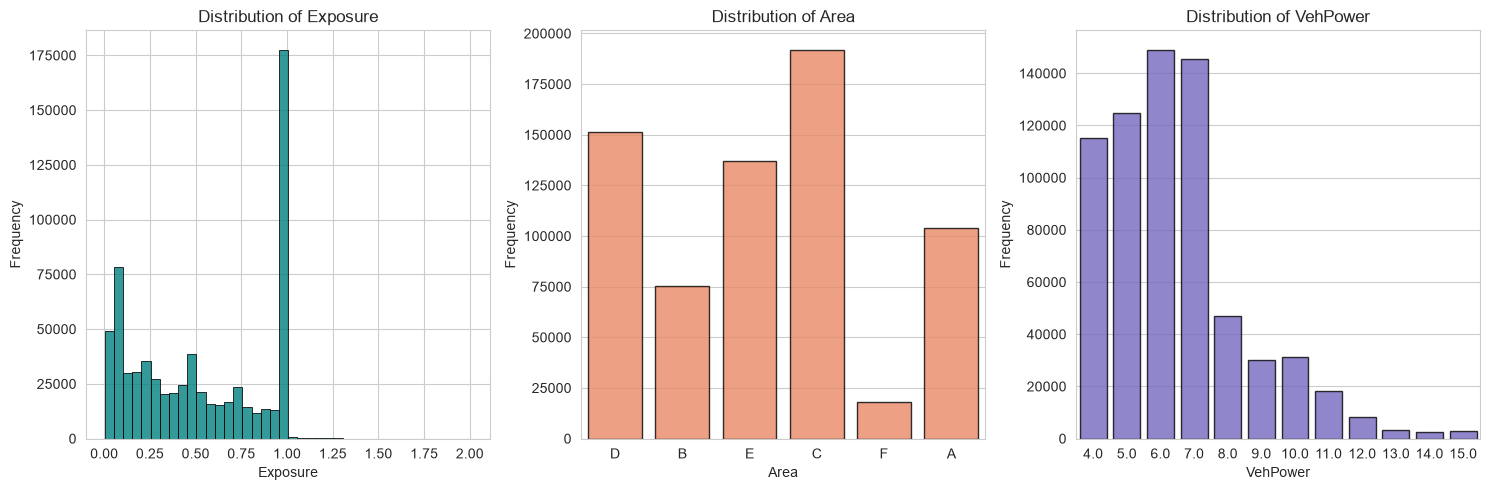

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(15,5))

sns.histplot(df['Exposure'], bins=40, color='teal', edgecolor='black', alpha=0.8, ax=axes[0])
axes[0].set_title('Distribution of Exposure')
axes[0].set_xlabel('Exposure')
axes[0].set_ylabel('Frequency')

sns.countplot(x=df['Area'], color='coral', edgecolor='black', alpha=0.8, ax=axes[1])
axes[1].set_title('Distribution of Area')
axes[1].set_xlabel('Area')
axes[1].set_ylabel('Frequency')

sns.countplot(x=df['VehPower'], color='slateblue', edgecolor='black', alpha=0.8, ax=axes[2])
axes[2].set_title('Distribution of VehPower')
axes[2].set_xlabel('VehPower')
axes[2].set_ylabel('Frequency')


plt.tight_layout()
plt.show()

---

**Observation :**

- Exposure: Most policies have an exposure close to 1, indicating full-year coverage, while shorter exposure periods are also common.
- Area: Area C has the highest number of policies, while Area F has the fewest.
- VehPower: Vehicle power is concentrated between 4 and 7, with frequencies decreasing as vehicle power increases beyond 7.

---


**Visualization 2**

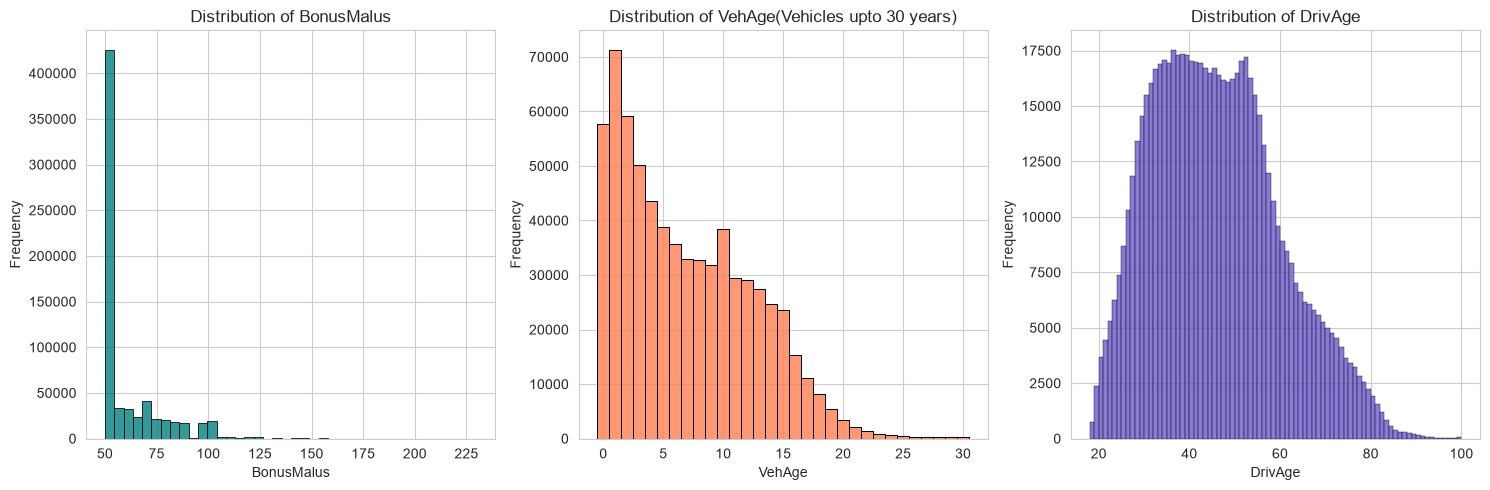

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(15,5))

sns.histplot(df['BonusMalus'], bins=40, color='teal', edgecolor='black', alpha=0.8, ax=axes[0])
axes[0].set_title('Distribution of BonusMalus')
axes[0].set_xlabel('BonusMalus')
axes[0].set_ylabel('Frequency')

sns.histplot(df['VehAge'][df['VehAge'] <= 30], discrete=True,color='coral', edgecolor='black', alpha=0.8, ax=axes[1])
axes[1].set_title('Distribution of VehAge(Vehicles upto 30 years)')
axes[1].set_xlabel('VehAge')
axes[1].set_ylabel('Frequency')

sns.histplot(df['DrivAge'], binwidth=1,color='slateblue', edgecolor='black', alpha=0.8, ax=axes[2])
axes[2].set_title('Distribution of DrivAge')
axes[2].set_xlabel('DrivAge')
axes[2].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

---

**Observation :**

- BonusMalus: Most policies have a BonusMalus value around 50, with fewer policies at higher values, resulting in a right-skewed distribution.
- VehAge: Most vehicles are relatively new, with frequency decreasing as vehicle age increases.
- DrivAge: Driver ages are concentrated mainly between 25 and 60 years, with fewer observations among older drivers.

---

**Visualization 3**

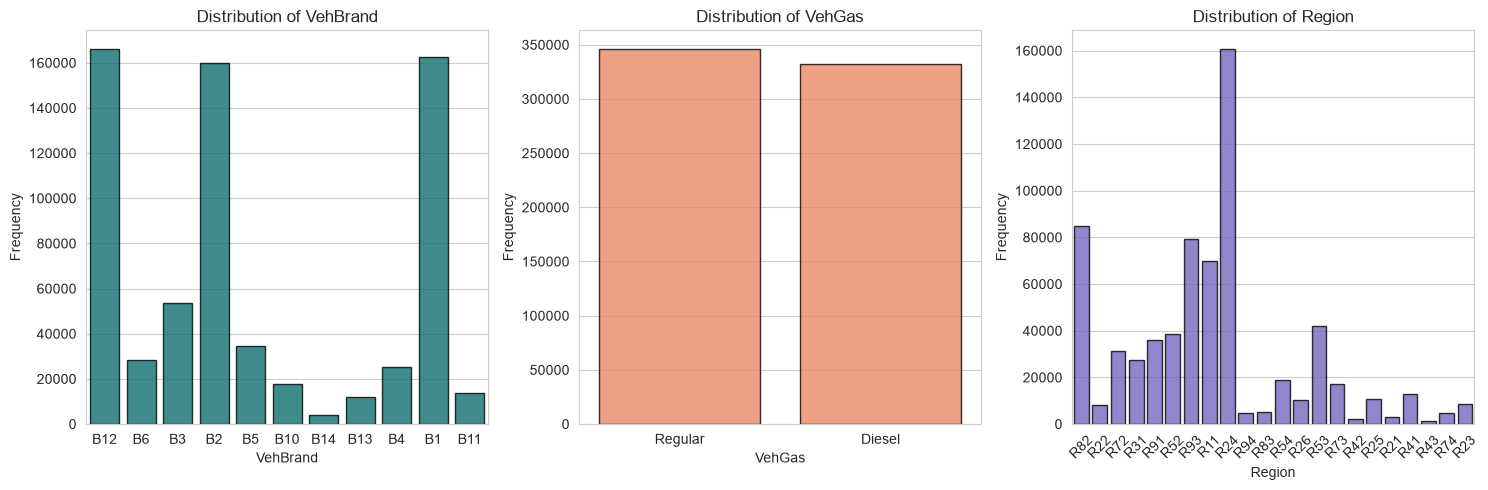

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(15,5))

sns.countplot(x=df['VehBrand'], color='teal', edgecolor='black', alpha=0.8, ax=axes[0])
axes[0].set_title('Distribution of VehBrand')
axes[0].set_xlabel('VehBrand')
axes[0].set_ylabel('Frequency')

sns.countplot(x=df['VehGas'],color='coral', edgecolor='black', alpha=0.8, ax=axes[1])
axes[1].set_title('Distribution of VehGas')
axes[1].set_xlabel('VehGas')
axes[1].set_ylabel('Frequency')

sns.countplot(x=df['Region'], color='slateblue', edgecolor='black', alpha=0.8, ax=axes[2])
axes[2].set_title('Distribution of Region')
axes[2].set_xlabel('Region')
axes[2].set_ylabel('Frequency')
axes[2].tick_params(axis='x',rotation = 45)

plt.tight_layout()
plt.show()

---

**Observation**

- VehBrand: Vehicle brands B12, B1, and B2 are the most frequent categories, while B14 has the lowest frequency.
- VehGas: Regular and diesel vehicles have relatively similar distributions, with regular vehicles slightly more common.
- Region: Policy distribution varies considerably across regions, with R24 having the highest frequency.

---

**Visualization 4**

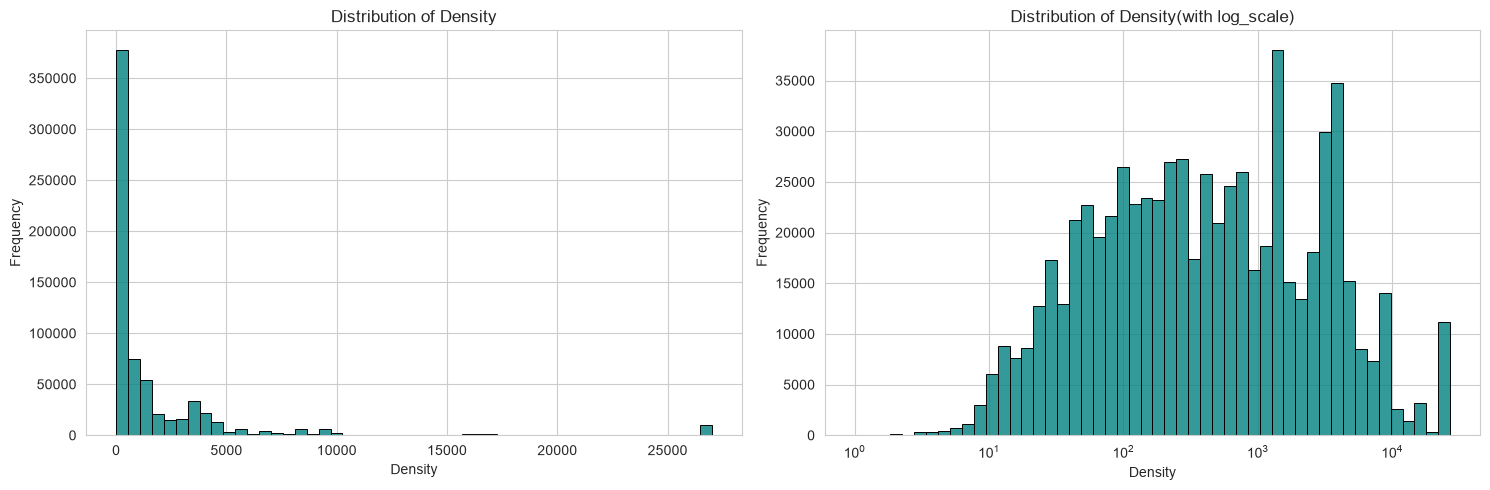

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(15,5))

sns.histplot(df['Density'], bins=50, color='teal', edgecolor='black', alpha=0.8, ax=axes[0])
axes[0].set_title('Distribution of Density')
axes[0].set_xlabel('Density')
axes[0].set_ylabel('Frequency')

sns.histplot(df['Density'], bins=50,  log_scale=True, color='teal', edgecolor='black', alpha=0.8, ax=axes[1])
axes[1].set_title('Distribution of Density(with log_scale)')
axes[1].set_xlabel('Density')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

---

**Observation**

- Density : The distribution is highly right-skewed, with most policies concentrated at low density values and a few extreme high-density observations.
- Density(with log) : The log scale reveals the spread across density values more clearly, showing that observations are distributed across a wide range of density levels.

---

### Bivariate Analysis

Understanding Claim Rate and Claim Frequency

- **Claim Rate:** Tells us the percentage of policies that had at least one claim.
- **Claim Frequency:** Tells us how often claims occurred relative to the total insurance exposure.

Using both gives us a better understanding of the overall claim behavior in the dataset.

##### Claim Rate:

$$
\boxed{
\text{Claim Rate} =
\frac{\text{Number of Policies with at Least One Claim}}
{\text{Total Number of Policies}}
}
$$





##### Claim Frequency:

$$
\boxed{
\text{Claim Frequency} =
\frac{\text{Total Claims}}
{\text{Total Exposure}}
}
$$

In [56]:
overall_claim_rate = df['HasClaim'].mean()
overall_claim_frequency = (df['ClaimNb'].sum())/df['Exposure'].sum()
print("Overall claim rate:", overall_claim_rate)
print("Overall claim frequency:", overall_claim_frequency)

Overall claim rate: 0.05023502499214617
Overall claim frequency: 0.10070308464041305


**Visualizations count** : 4


=== Area ===
      policies  claims     exposure  claim_rate  claim_frequency
Area                                                            
F        17954  1131.0    8129.2341      0.0588           0.1391
E       137167  7805.0   63819.3143      0.0532           0.1223
D       151596  8428.0   77120.1917      0.0521           0.1093
C       191880  9875.0  104449.0038      0.0488           0.0945
B        75459  3800.0   43012.3239      0.0481           0.0883
A       103957  5063.0   61969.3777      0.0465           0.0817


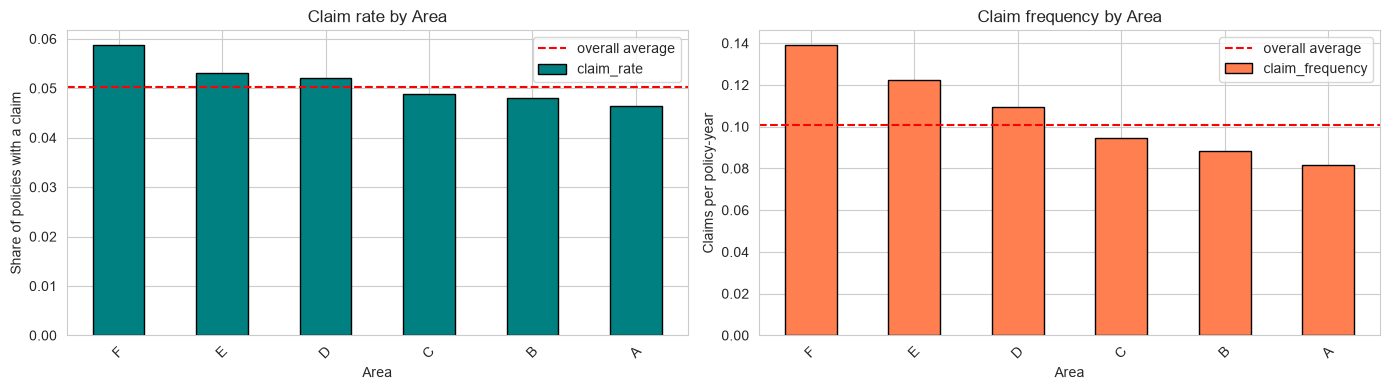


=== VehBrand ===
          policies  claims    exposure  claim_rate  claim_frequency
VehBrand                                                           
B12         166024  8859.0  64808.6087      0.0497           0.1367
B11          13585   721.0   6887.8173      0.0501           0.1047
B5           34753  2020.0  19992.0627      0.0551           0.1010
B3           53395  2818.0  28592.8763      0.0500           0.0986
B13          12178   649.0   6772.0322      0.0503           0.0958
B4           25179  1312.0  13775.4961      0.0498           0.0952
B6           28548  1462.0  15684.9536      0.0486           0.0932
B1          162736  8677.0  95351.0596      0.0502           0.0910
B10          17707   858.0   9496.0141      0.0461           0.0904
B2          159861  8560.0  94864.0571      0.0508           0.0902
B14           4047   166.0   2274.4677      0.0395           0.0730


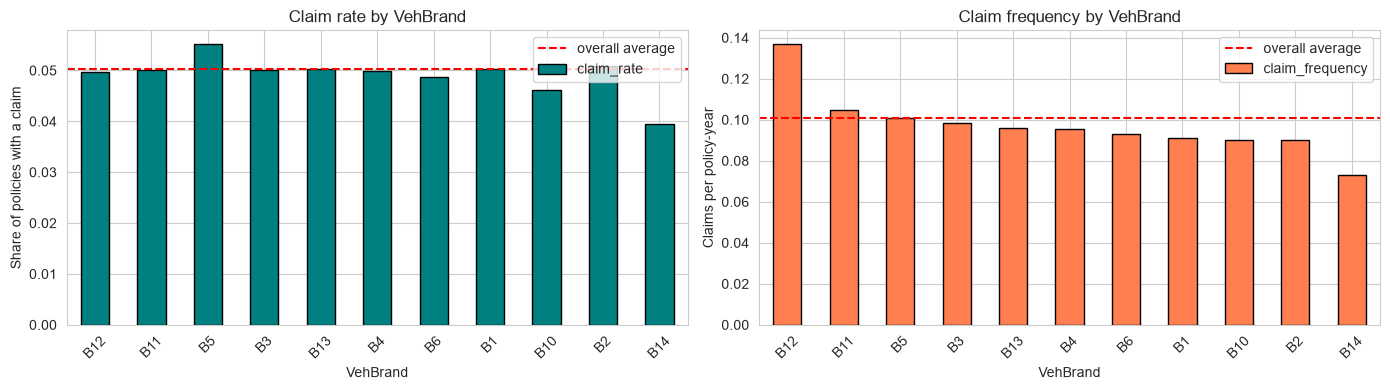


=== VehGas ===
         policies   claims     exposure  claim_rate  claim_frequency
VehGas                                                              
Regular    345877  19454.0  187838.5523      0.0531           0.1036
Diesel     332136  16648.0  170660.8931      0.0473           0.0976


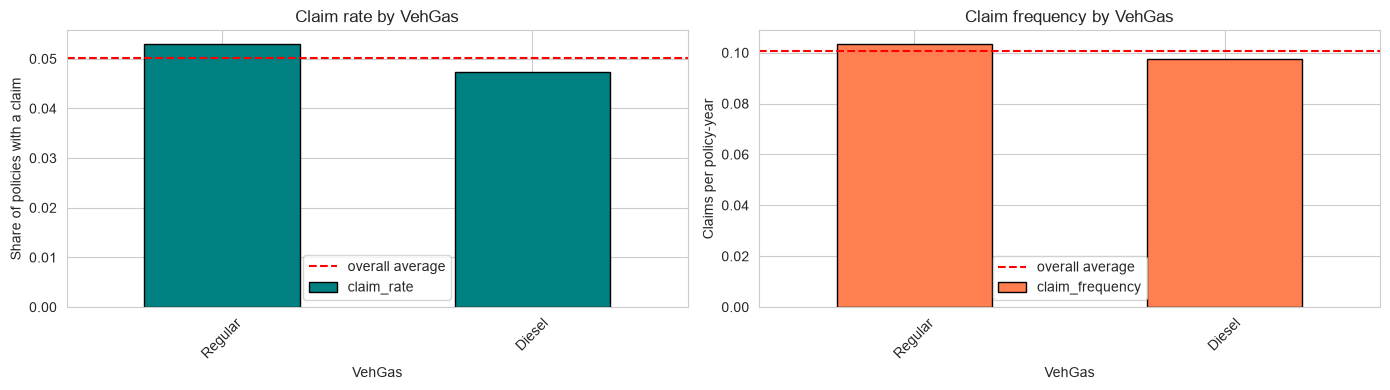


=== Region ===
        policies  claims     exposure  claim_rate  claim_frequency
Region                                                            
R94         4516   247.0    1765.9354      0.0487           0.1399
R21         3026   160.0    1205.8315      0.0492           0.1327
R11        69791  3978.0   30208.6420      0.0532           0.1317
R22         7994   439.0    3574.4102      0.0527           0.1228
R82        84752  5032.0   45347.4173      0.0562           0.1110
R42         2200   133.0    1209.1158      0.0564           0.1100
R93        79315  3907.0   35790.3210      0.0457           0.1092
R74         4567   259.0    2395.9945      0.0530           0.1081
R91        35805  1547.0   14736.1042      0.0388           0.1050
R31        27285  1176.0   11497.9743      0.0400           0.1023
R26        10492   511.0    5025.3586      0.0465           0.1017
R43         1326    57.0     564.0129      0.0407           0.1011
R73        17141   688.0    7020.1086      0.0

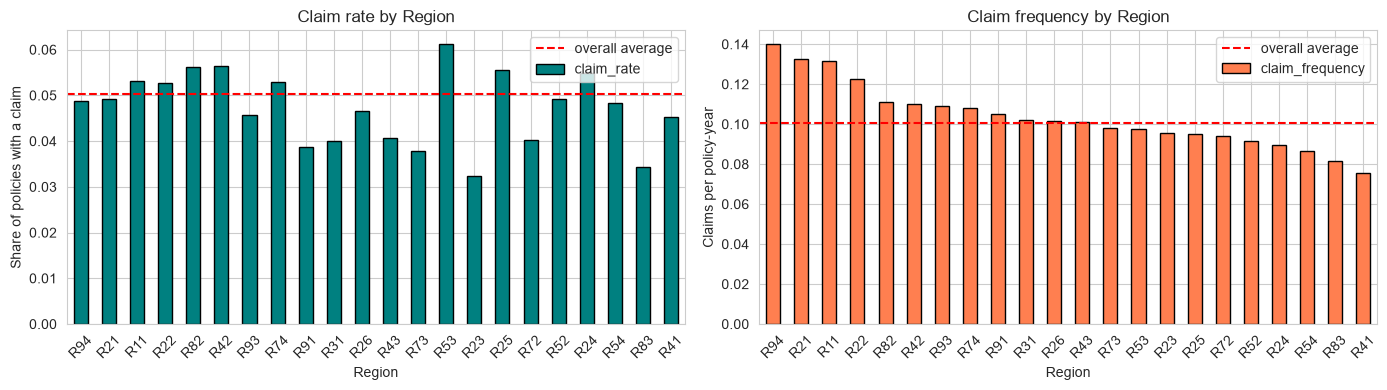

In [57]:
# dividing the values in the cat_features groupwise.
# building a table with feature wise insurance policy data
# Visualizing them using bar plots with overall claim rate and claim frequency comparision


cat_features = ['Area', 'VehBrand', 'VehGas', 'Region']
tables = {}

for feature in cat_features:

    #creating group wise data for features in cat_features
    grouped = df.groupby(feature, observed=True)
    table = pd.DataFrame({
        'policies': grouped['IDpol'].count(),
        'claims': grouped['ClaimNb'].sum(),
        'exposure': grouped['Exposure'].sum(),
        'claim_rate': grouped['HasClaim'].mean(),
    })
    table['claim_frequency'] = table['claims'] / table['exposure']


    table = table.sort_values('claim_frequency', ascending=False)


    tables[feature] = table

    print(f"\n=== {feature} ===")
    print(table.round(4))

    #plots
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    table['claim_rate'].plot(kind='bar', color='teal', edgecolor='black', ax=axes[0])
    axes[0].axhline(overall_claim_rate, color='red', linestyle='--', label='overall average')
    axes[0].set_title(f'Claim rate by {feature}')
    axes[0].set_xlabel(feature)
    axes[0].set_ylabel('Share of policies with a claim')
    axes[0].tick_params(axis='x', rotation=45)
    axes[0].legend()

    table['claim_frequency'].plot(kind='bar', color='coral', edgecolor='black', ax=axes[1])
    axes[1].axhline(overall_claim_frequency, color='red', linestyle='--', label='overall average')
    axes[1].set_title(f'Claim frequency by {feature}')
    axes[1].set_xlabel(feature)
    axes[1].set_ylabel('Claims per policy-year')
    axes[1].tick_params(axis='x', rotation=45)
    axes[1].legend()

    plt.tight_layout()
    plt.show()

---

**Observation :**
- Area F is the smallest group (17,954 policies, 2.6%), but the pattern is steady across all six areas, so it does not rest on one group.
- Area: Area F has the highest claim rate and claim frequency, while Area A has the lowest claim rate and frequency.
- VehBrand: Claim rates are relatively similar across vehicle brands, but B5 has the highest claim rate and B12 has the highest claim frequency.
- VehGas: Regular vehicles have a slightly higher claim rate and claim frequency than diesel vehicles.
- Region: Claim rates and frequencies vary across regions, with R53 showing the highest claim rate and R94 showing the highest claim frequency.

---


##### Numerical Features

**Visualization count** : 6


=== DrivAge ===
           policies  claims    exposure  claim_rate  claim_frequency
DrivAge                                                             
(17, 25]      38895  2841.0  16227.9033      0.0674           0.1751
(25, 35]     149183  6662.0  69266.7781      0.0423           0.0962
(35, 45]     170352  8397.0  87702.3363      0.0468           0.0957
(45, 55]     161899  9256.0  89268.7764      0.0538           0.1037
(55, 65]      90691  4748.0  51775.5533      0.0494           0.0917
(65, 75]      48049  2873.0  30766.9935      0.0567           0.0934
(75, 100]     18944  1325.0  13491.1047      0.0654           0.0982
Policies in the bands: 678013 of 678013


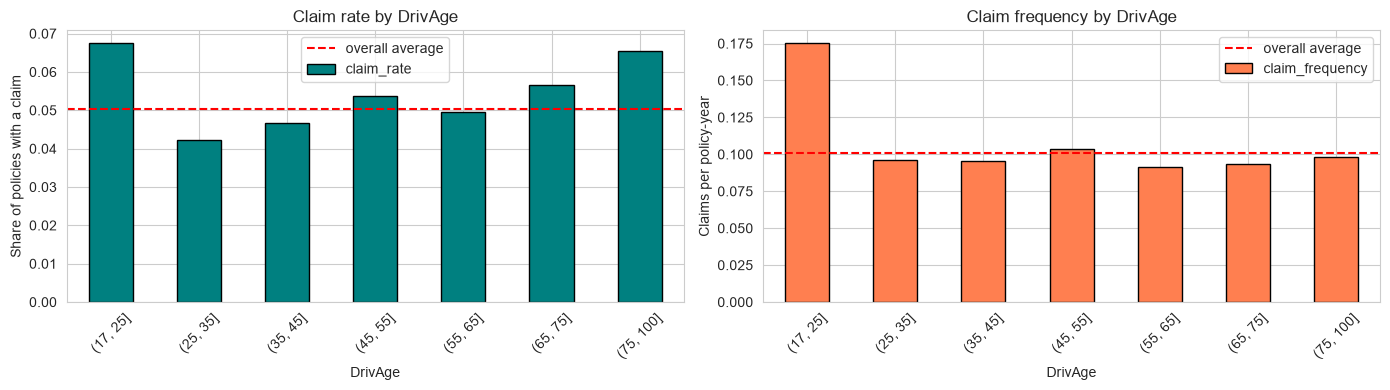


=== VehAge ===
           policies   claims    exposure  claim_rate  claim_frequency
VehAge                                                               
(-1, 2]      188147  10904.0  79176.0553      0.0545           0.1377
(2, 5]       132490   6743.0  72040.1238      0.0479           0.0936
(5, 10]      171594   9846.0  99008.9164      0.0542           0.0994
(10, 15]     134063   6648.0  77990.9754      0.0468           0.0852
(15, 20]      43397   1685.0  25136.1586      0.0372           0.0670
(20, 100]      8322    276.0   5147.2160      0.0309           0.0536
Policies in the bands: 678013 of 678013


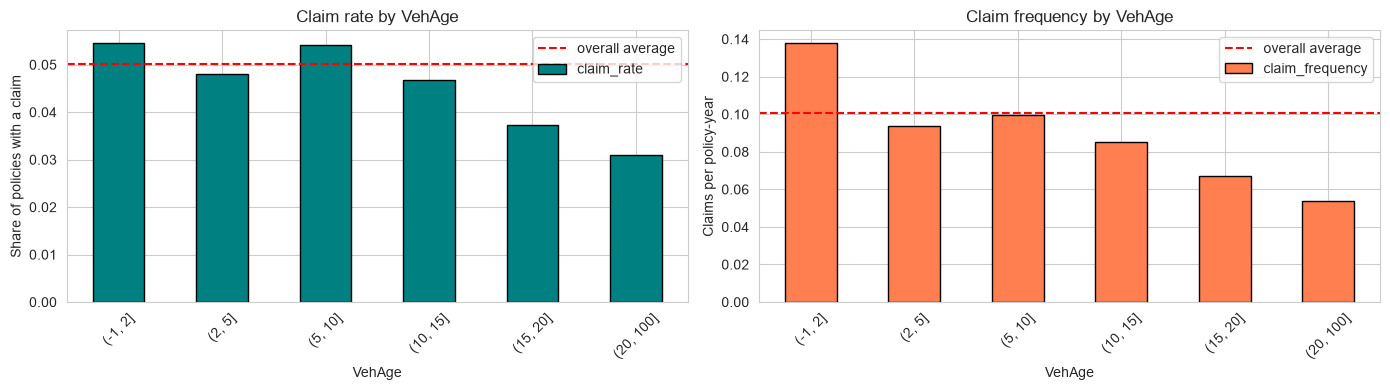


=== VehPower ===
          policies  claims    exposure  claim_rate  claim_frequency
VehPower                                                           
4.0         115349  5699.0  60073.6373      0.0461           0.0949
5.0         124821  7278.0  68173.3488      0.0551           0.1068
6.0         148976  8381.0  82524.2102      0.0532           0.1016
7.0         145401  7627.0  77950.4567      0.0496           0.0978
8.0          46956  1922.0  22684.6163      0.0386           0.0847
9.0          30085  1754.0  15348.2137      0.0551           0.1143
10.0         31354  1789.0  15375.0108      0.0539           0.1164
11.0         18352   897.0   8497.7785      0.0459           0.1056
12.0          8214   359.0   3792.0383      0.0414           0.0947
13.0          3229   153.0   1637.2553      0.0455           0.0934
14.0          2350   119.0   1182.3504      0.0460           0.1006
15.0          2926   124.0   1260.5292      0.0410           0.0984
Policies in the bands: 678013 

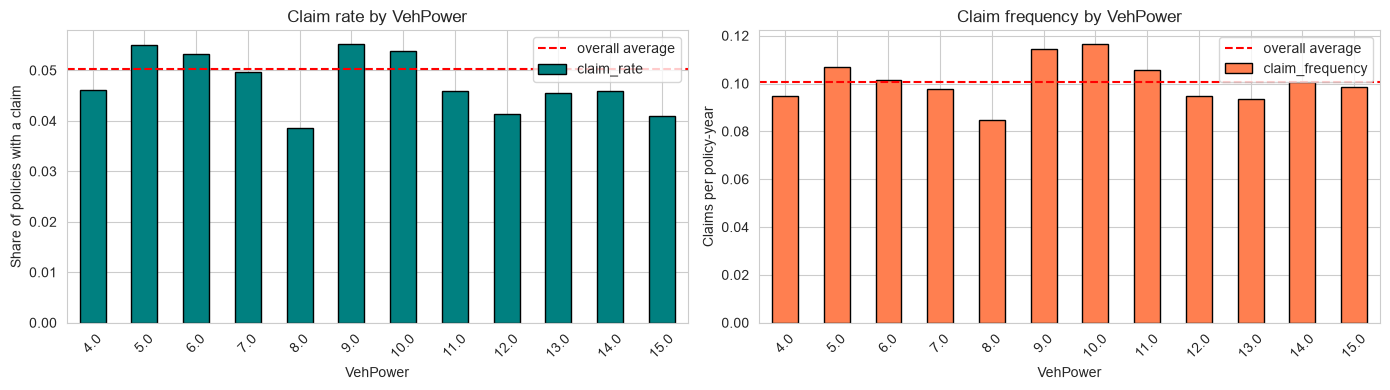


=== BonusMalus ===
            policies   claims     exposure  claim_rate  claim_frequency
BonusMalus                                                             
(49, 50]      384156  18056.0  225233.1309      0.0446           0.0802
(50, 60]       94446   4553.0   47985.4970      0.0459           0.0949
(60, 70]       56929   3671.0   26497.7135      0.0604           0.1385
(70, 85]       80098   4471.0   34177.6498      0.0527           0.1308
(85, 100]      54590   4009.0   21034.1352      0.0679           0.1906
(100, 230]      7794   1342.0    3571.3190      0.1556           0.3758
Policies in the bands: 678013 of 678013


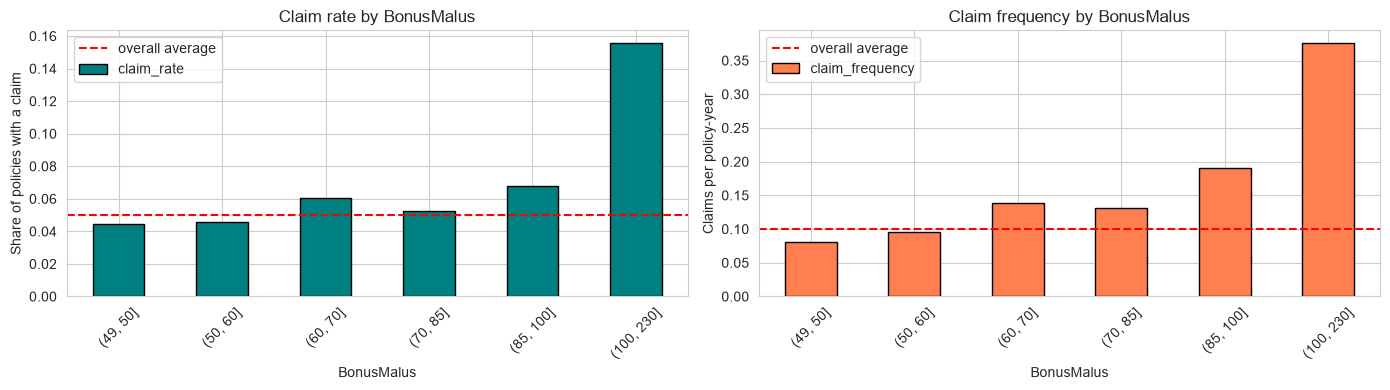


=== Density ===
                   policies  claims    exposure  claim_rate  claim_frequency
Density                                                                     
(0.999, 33.0]         68910  3257.0  41630.1724      0.0453           0.0782
(33.0, 67.0]          68430  3496.0  39778.8372      0.0484           0.0879
(67.0, 122.0]         66925  3340.0  37363.9929      0.0478           0.0894
(122.0, 214.0]        67253  3403.0  36740.3867      0.0478           0.0926
(214.0, 393.0]        68699  3465.0  36502.5396      0.0479           0.0949
(393.0, 716.0]        66699  3626.0  35538.5920      0.0512           0.1020
(716.0, 1313.0]       69809  4057.0  36512.0947      0.0540           0.1111
(1313.0, 2715.0]      68036  3798.0  32974.1092      0.0524           0.1152
(2715.0, 4128.0]      67824  3817.0  31813.6477      0.0528           0.1200
(4128.0, 27000.0]     65428  3843.0  29645.0731      0.0548           0.1296
Policies in the bands: 678013 of 678013


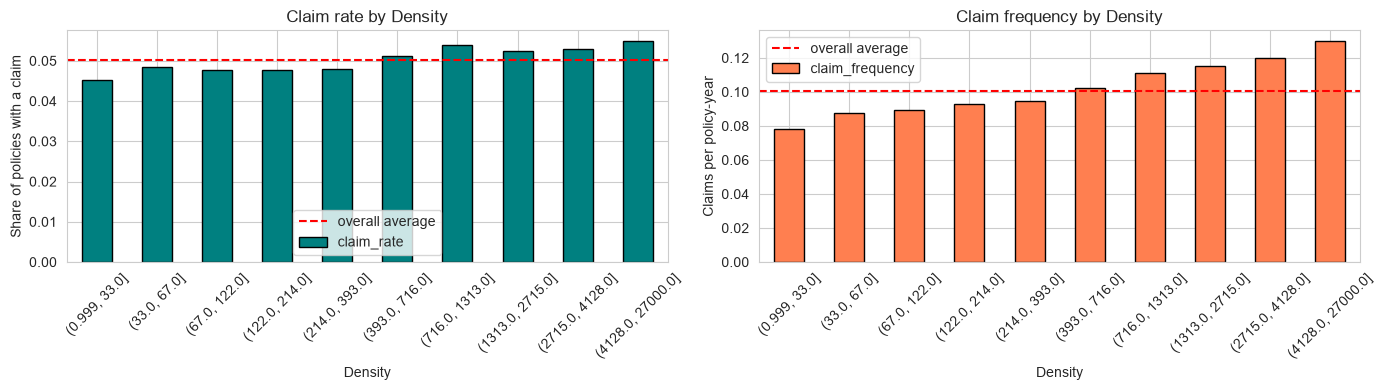


=== Exposure ===
             policies   claims     exposure  claim_rate  claim_frequency
Exposure                                                                
(0.0, 0.1]     127596   3460.0    7530.1355      0.0256           0.4595
(0.1, 0.25]     95216   3671.0   17434.6300      0.0366           0.2106
(0.25, 0.5]    131302   6481.0   51388.7400      0.0462           0.1261
(0.5, 0.75]     92494   5968.0   58574.5900      0.0606           0.1019
(0.75, 1.0]    230181  16468.0  222208.0100      0.0677           0.0741
(1.0, inf]       1224     54.0    1363.3400      0.0417           0.0396
Policies in the bands: 678013 of 678013


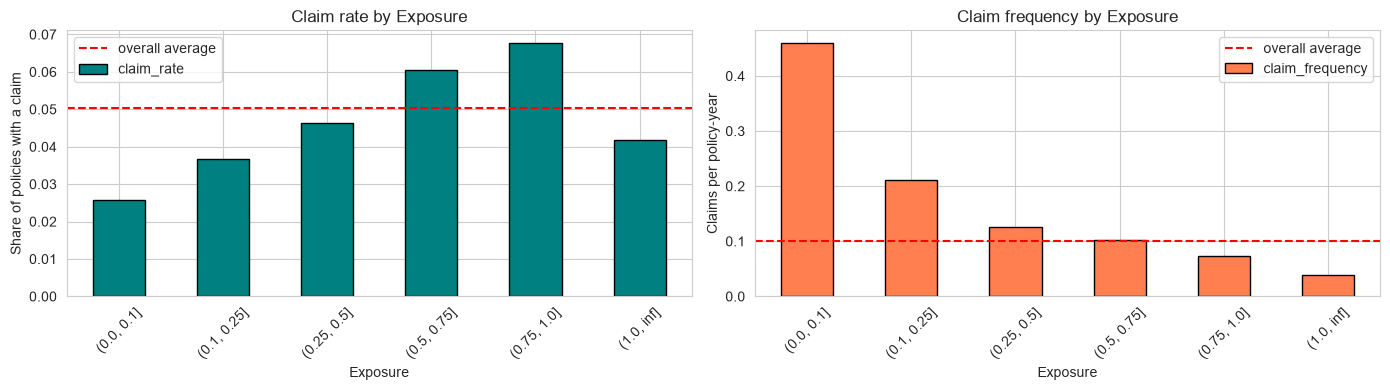

In [58]:
#Using same kind of approach for numerical features

numeric_features = ['DrivAge', 'VehAge', 'VehPower', 'BonusMalus', 'Density', 'Exposure']


edges = {
    'DrivAge':    [17, 25, 35, 45, 55, 65, 75, 100],
    'VehAge':     [-1, 2, 5, 10, 15, 20, 100],
    'BonusMalus': [49, 50, 60, 70, 85, 100, 230],     # (49, 50] holds the value 50 on its own
    'Exposure':   [0, 0.1, 0.25, 0.5, 0.75, 1.0, np.inf],
}

num_tables = {}

for feature in numeric_features:


    if feature in edges:
        bands = pd.cut(df[feature], bins=edges[feature])             # custom edge band
    elif feature == 'Density':
        bands = pd.qcut(df[feature], q=10, duplicates='drop')        # 10 equal-sized groups
    else:
        bands = df[feature]                                          # using the value itself


    grouped = df.groupby(bands, observed=True)
    table = pd.DataFrame({
        'policies': grouped['IDpol'].count(),
        'claims': grouped['ClaimNb'].sum(),
        'exposure': grouped['Exposure'].sum(),
        'claim_rate': grouped['HasClaim'].mean(),
    })
    table['claim_frequency'] = table['claims'] / table['exposure']

    num_tables[feature] = table

    print(f"\n=== {feature} ===")
    print(table.round(4))
    print("Policies in the bands:", table['policies'].sum(), "of", len(df))

    # plots
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    table['claim_rate'].plot(kind='bar', color='teal', edgecolor='black', ax=axes[0])
    axes[0].axhline(overall_claim_rate, color='red', linestyle='--', label='overall average')
    axes[0].set_title(f'Claim rate by {feature}')
    axes[0].set_xlabel(feature)
    axes[0].set_ylabel('Share of policies with a claim')
    axes[0].tick_params(axis='x', rotation=45)
    axes[0].legend()

    table['claim_frequency'].plot(kind='bar', color='coral', edgecolor='black', ax=axes[1])
    axes[1].axhline(overall_claim_frequency, color='red', linestyle='--', label='overall average')
    axes[1].set_title(f'Claim frequency by {feature}')
    axes[1].set_xlabel(feature)
    axes[1].set_ylabel('Claims per policy-year')
    axes[1].tick_params(axis='x', rotation=45)
    axes[1].legend()

    plt.tight_layout()
    plt.show()

---

**Observation**

- DrivAge: Drivers aged 17–25 have the highest claim frequency, while claim rates are also elevated among the youngest and oldest driver groups.
- VehAge: Claim frequency generally decreases as vehicle age increases, with vehicles aged 1–2 years showing the highest claim rate.
- VehPower: Claim rates vary across vehicle power categories, while claim frequency is highest for vehicles with power ratings of 10 and 9.
- BonusMalus: Claim rate and claim frequency generally increase with higher BonusMalus values, with the highest values observed in the 100–230 range.
- Density: Claim rate and claim frequency generally increase with population density, with higher-density areas showing greater claim frequency.
- Exposure: Claim rate generally increases with exposure up to the 0.75–1.0 range, while claim frequency decreases as exposure increases.


---

**Visualization 14**

##### Correlation Heatmap

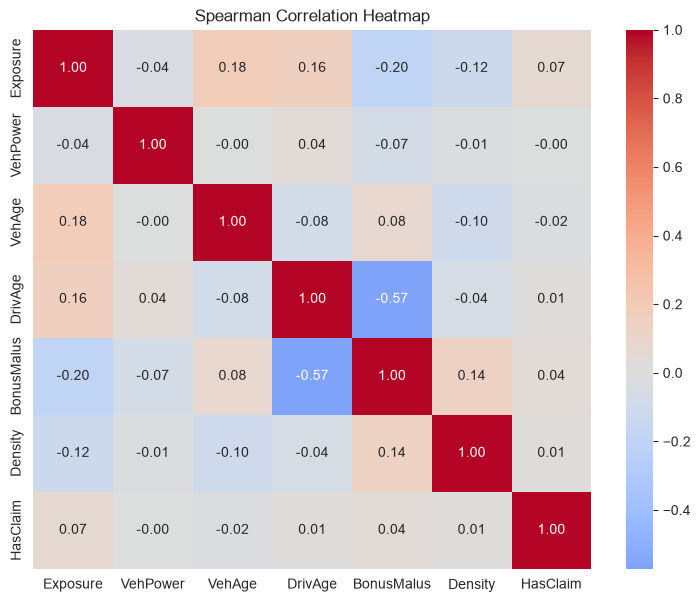

In [59]:
# IDpol is only an identifier and ClaimNb is what HasClaim is made from, so both are left out
numeric_df = df.select_dtypes(include="number").drop(columns=["IDpol", "ClaimNb"])

plt.figure(figsize=(9, 7))

sns.heatmap(numeric_df.corr(method="spearman"),annot=True,fmt=".2f",cmap="coolwarm",center=0)

plt.title("Spearman Correlation Heatmap")
plt.show()

---

**Observation:**

- Spearman Correlation: Most features have weak correlations with HasClaim. The strongest relationship among the features is a moderate negative correlation between DrivAge and BonusMalus (-0.57), while Exposure has a weak positive correlation with HasClaim (0.07).

---

**Visualization 15**

#### BonusMalus vs HasClaim Boxplot

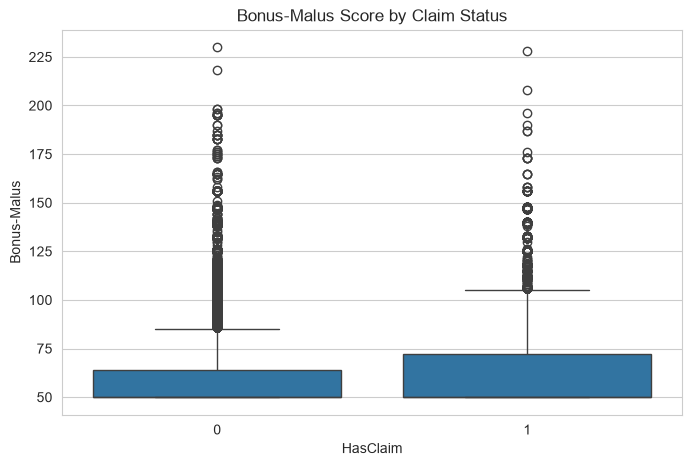

In [60]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="HasClaim",
    y="BonusMalus"
)

plt.title("Bonus-Malus Score by Claim Status")
plt.xlabel("HasClaim")
plt.ylabel("Bonus-Malus")
plt.show()

---

**Observation :**
- BonusMalus by Claim Status: Policies with claims (HasClaim = 1) show a higher median BonusMalus score and a wider spread than policies without claims, suggesting that higher BonusMalus scores are associated with increased claim likelihood.

---

**Visualization 16**

##### VehAge vs HasClaim

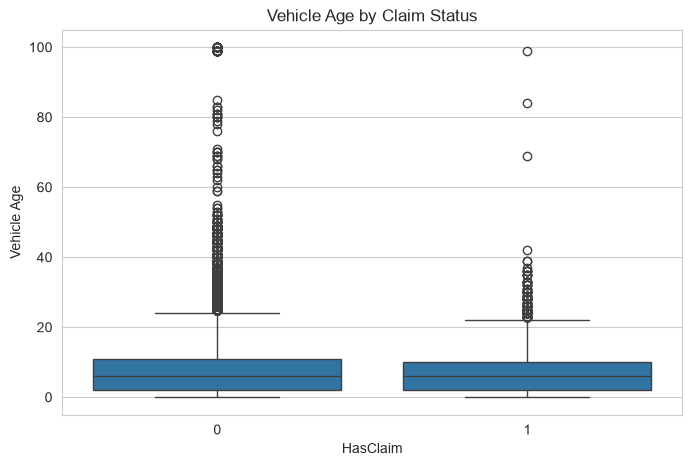

In [61]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="HasClaim",
    y="VehAge"
)

plt.title("Vehicle Age by Claim Status")
plt.xlabel("HasClaim")
plt.ylabel("Vehicle Age")
plt.show()

---

**Observation :**

- Vehicle Age by Claim Status: Vehicle age distributions are broadly similar for policies with and without claims, although claim-free policies show more extreme age outliers. Vehicle age alone does not appear to clearly distinguish claim status.

---

**Visualization 17**

##### Distribution and skewness of numeric features (histograms)

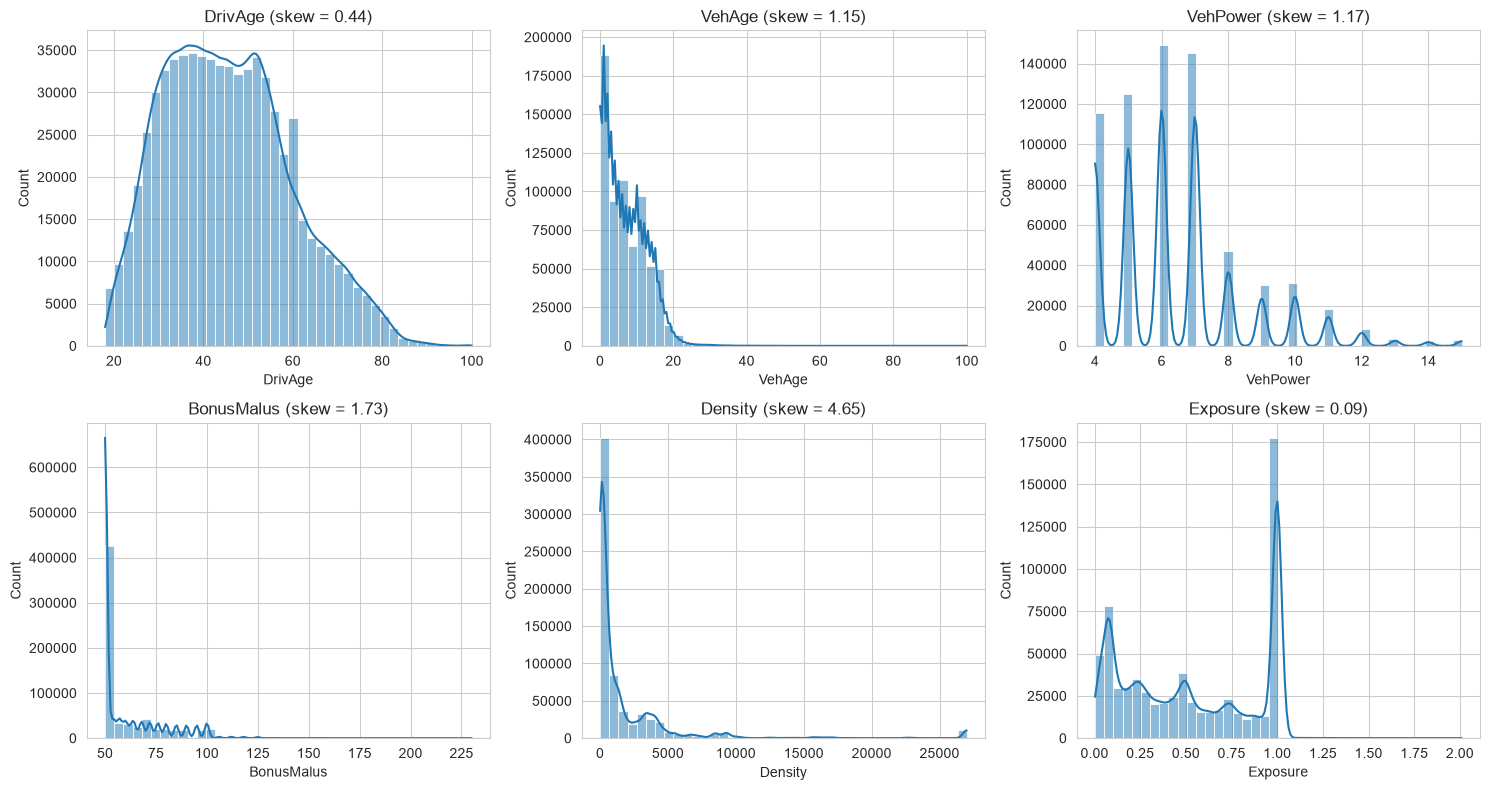

In [62]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), numeric_features): #created in correlation analysis code cell
    sns.histplot(df[c], bins=40, kde=True, ax=ax)
    ax.set_title(f"{c} (skew = {df[c].skew():.2f})")
plt.tight_layout()
plt.show()

In [63]:
skew_table = df[numeric_features].skew()
print(skew_table.sort_values(ascending=False).round(2))

Density       4.65
BonusMalus    1.73
VehPower      1.17
VehAge        1.15
DrivAge       0.44
Exposure      0.09
dtype: float64


In [64]:
print(df[numeric_features].agg(["mean", "median", "min", "max"]).round(2)) #comapring mean and median

        DrivAge  VehAge  VehPower  BonusMalus   Density  Exposure
mean       45.5    7.04      6.45       59.76   1792.42      0.53
median     44.0    6.00      6.00       50.00    393.00      0.49
min        18.0    0.00      4.00       50.00      1.00      0.00
max       100.0  100.00     15.00      230.00  27000.00      2.01


In [65]:
# checking if log transformation will bring a change in the skewness

for c in ["Density", "BonusMalus", "VehPower", "VehAge"]:
    before = df[c].skew()
    after = np.log1p(df[c]).skew()
    print(c, "- before:", round(before, 2), "- after log:", round(after, 2))

Density - before: 4.65 - after log: 0.05
BonusMalus - before: 1.73 - after log: 1.36
VehPower - before: 1.17 - after log: 0.46
VehAge - before: 1.15 - after log: -0.55


---
**Observation :**

- DrivAge: Slight positive skew (0.44), with most drivers concentrated in the middle-age range.
- VehAge: Positively skewed (1.15), with most vehicles being relatively new.
- VehPower: Positively skewed (1.17), with lower vehicle power categories occurring more frequently.
- BonusMalus: Positively skewed (1.73), with most values concentrated around 50 and fewer policies having higher scores.
- Density: Highly positively skewed (4.65), with most policies in low-density areas and a few extreme high-density values.
- Exposure: Nearly symmetric (skew = 0.09), with a strong concentration at full-year exposure (1.0).

---

In [66]:
print("VehAge > 30 :", (df["VehAge"] > 30).sum())
print("DrivAge > 90:", (df["DrivAge"] > 90).sum())
print("Exposure > 1:", (df["Exposure"] > 1).sum())

VehAge > 30 : 1116
DrivAge > 90: 401
Exposure > 1: 1224


In [67]:
(df["BonusMalus"] == 50).mean()

np.float64(0.5665909060740724)

**Visualization 18**

##### Scatter Plots : Bonus-Malus vs Driver Age

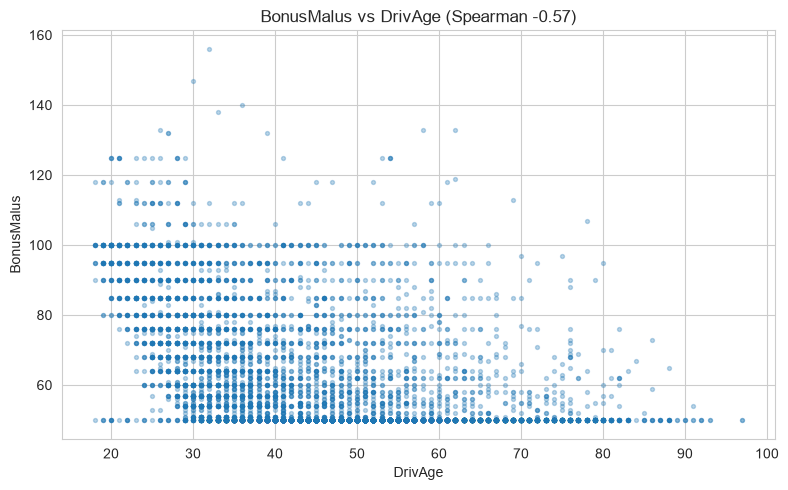

In [68]:
sample = df.sample(n=10000, random_state=42)

# Keep only the most meaningful feature relationship
pairs = [
    ('DrivAge', 'BonusMalus')
]

# Draw the scatter plot
plt.figure(figsize=(8, 5))

x, y = pairs[0]

corr_value = df[x].corr(df[y], method='spearman')

plt.scatter(
    sample[x],
    sample[y],
    alpha=0.3,
    s=8
)

plt.title(f'{y} vs {x} (Spearman {corr_value:.2f})')
plt.xlabel(x)
plt.ylabel(y)

plt.tight_layout()
plt.show()

---

**Observation:**

- BonusMalus vs DrivAge: A moderate negative Spearman correlation (-0.57) indicates that BonusMalus scores generally decrease as driver age increases, with younger drivers tending to have higher scores.

---

##### Boxplots of numeric features

**Visualization 19**

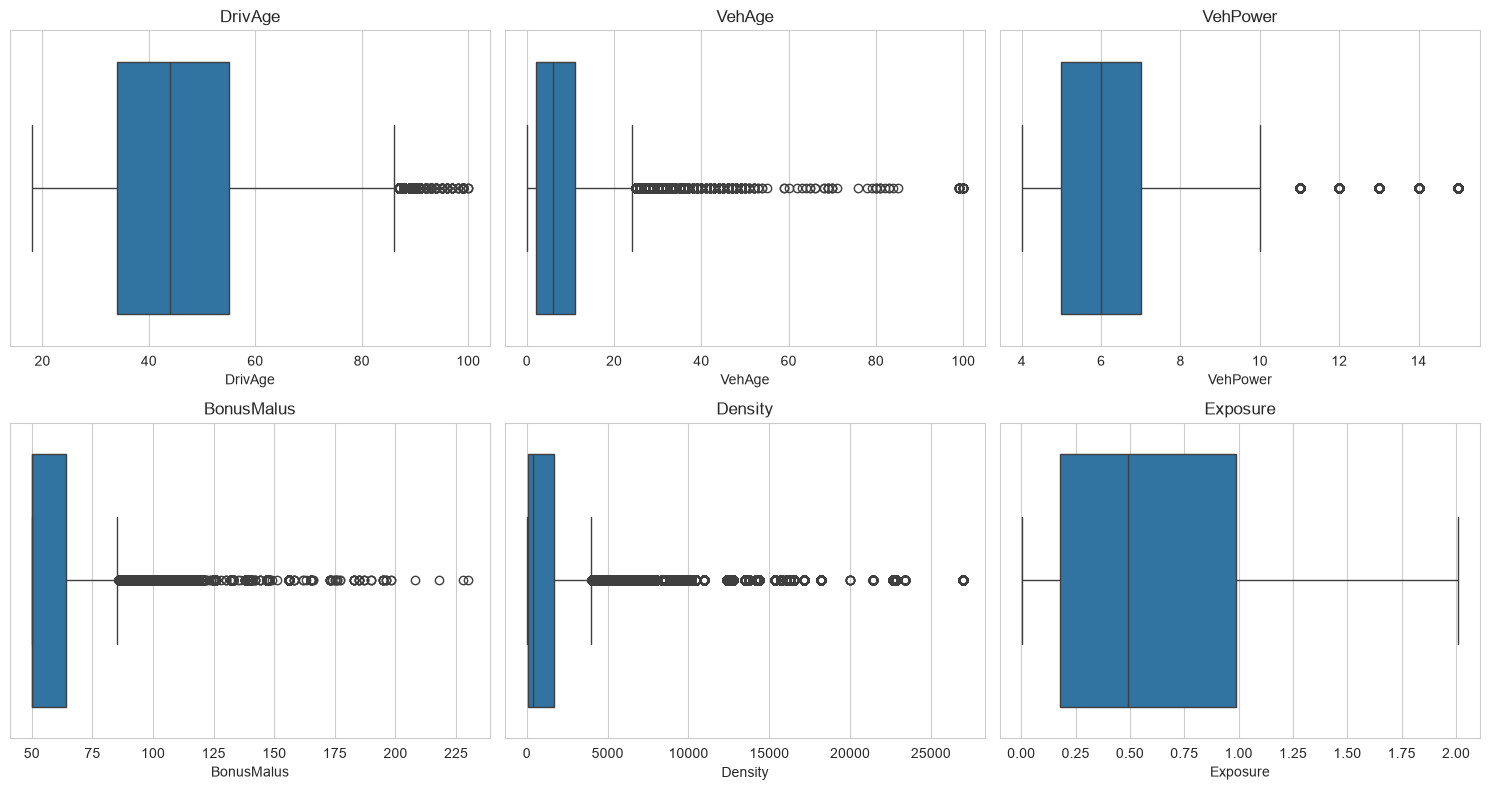

In [69]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), numeric_features):
    sns.boxplot(x=df[c], ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

---

**Observation :**

- DrivAge: Several high-age outliers are present, indicating a small number of policies involving older drivers.
- VehAge: The distribution is right-skewed, with numerous high-age outliers and most vehicles concentrated at lower ages.
- VehPower: Most vehicles have power ratings between 5 and 7, with a few high-power outliers.
- BonusMalus: Numerous high-value outliers are present beyond the main concentration around 50.
- Density: The distribution contains many extreme high-density outliers, indicating substantial variation in population density.
- Exposure: Exposure ranges from 0 to 2, with a median around 0.5 and no prominent outliers in the boxplot.

---

In [70]:
print("VehAge == 100  :", (df["VehAge"] == 100).sum())
print("DrivAge == 100 :", (df["DrivAge"] == 100).sum())
print("Density == max :", (df["Density"] == df["Density"].max()).sum())

VehAge == 100  : 25
DrivAge == 100 : 3
Density == max : 10515


In [71]:
for c in numeric_features:
    q1 = df[c].quantile(0.25)
    q3 = df[c].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_out = ((df[c] < lower) | (df[c] > upper)).sum()
    print(c, "- outliers:", n_out, f"({n_out / len(df) * 100:.2f}%)")

DrivAge - outliers: 1275 (0.19%)
VehAge - outliers: 3114 (0.46%)
VehPower - outliers: 35071 (5.17%)
BonusMalus - outliers: 62384 (9.20%)
Density - outliers: 77566 (11.44%)
Exposure - outliers: 0 (0.00%)


##### Interaction heatmap, driver age x vehicle age

**Visualization 20**

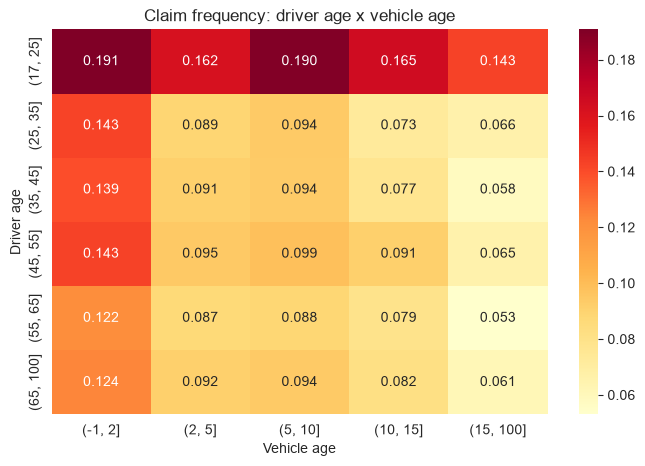

In [72]:

drv = pd.cut(df["DrivAge"], [17, 25, 35, 45, 55, 65, 100])
veh = pd.cut(df["VehAge"], [-1, 2, 5, 10, 15, 100])

claims = df.pivot_table(index=drv, columns=veh, values="ClaimNb", aggfunc="sum", observed=True)
expo = df.pivot_table(index=drv, columns=veh, values="Exposure", aggfunc="sum", observed=True)

plt.figure(figsize=(8, 5))
sns.heatmap(claims / expo, annot=True, fmt=".3f", cmap="YlOrRd")
plt.title("Claim frequency: driver age x vehicle age")
plt.xlabel("Vehicle age")
plt.ylabel("Driver age")
plt.show()

---

**Observation :**

- Claim Frequency by Driver Age and Vehicle Age: The highest claim frequency (0.191) occurs among drivers aged 17–25 with vehicles aged up to 2 years. Claim frequency generally decreases with increasing driver age and vehicle age.

---




###
### **3.8 Key EDA Insights**

---

- Target imbalance: Approximately 95% of policies have no claims and 5% have claims, indicating a severe class imbalance (18.9:1).
- BonusMalus: Higher BonusMalus scores are associated with higher claim rates and claim frequency.
- Driver and vehicle age: Drivers aged 17–25 with vehicles aged up to 2 years show the highest claim frequency.
- Exposure: Most policies have full-year exposure (Exposure = 1), while claim frequency generally decreases as exposure increases.
- Geographical differences: Claim rates and frequencies vary across regions and areas.
- Correlation: Most numerical features have weak correlations with HasClaim; DrivAge and BonusMalus show a moderate negative correlation (-0.57).
- Modelling implication: Due to class imbalance, evaluate models using recall, precision, F1-score, and PR-AUC, not accuracy alone.
       
---

### **4. Data Cleaning & Preprocessing**

### **4.1 Missing Value Treatment**

In [73]:
df_clean = df.copy() #create a copy of the dataset

In [74]:
df_clean.head()

,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,HasClaim
0,1.0,1.0,0.10,D,5.0,0.0,55.0,50.0,B12,Regular,1217.0,R82,1
1,3.0,1.0,0.77,D,5.0,0.0,55.0,50.0,B12,Regular,1217.0,R82,1
2,5.0,1.0,0.75,B,6.0,2.0,52.0,50.0,B12,Diesel,54.0,R22,1
3,10.0,1.0,0.09,B,7.0,0.0,46.0,50.0,B12,Diesel,76.0,R72,1
4,11.0,1.0,0.84,B,7.0,0.0,46.0,50.0,B12,Diesel,76.0,R72,1


In [75]:

#finding missing values
df_clean.isnull().sum()


IDpol         0
ClaimNb       0
Exposure      0
Area          0
VehPower      0
VehAge        0
DrivAge       0
BonusMalus    0
VehBrand      0
VehGas        0
Density       0
Region        0
HasClaim      0
dtype: int64

In [76]:

#changing the category data types to str
df_clean['Area'] = df_clean['Area'].astype('str')
df_clean['VehBrand'] = df_clean['VehBrand'].astype('str')
df_clean['Region'] = df_clean['Region'].astype('str')
df_clean['VehGas'] = df_clean['VehGas'].astype('str')


In [77]:

print("Before cleaning")
print(df_clean['VehGas'].value_counts())

# remove the quotation marks around the values
df_clean['VehGas'] = df_clean['VehGas'].astype(str).str.strip("'")
print("----------------------------------------------------------")
print("After Cleaning")
print(df_clean['VehGas'].value_counts())

Before cleaning
VehGas
Regular    345877
Diesel     332136
Name: count, dtype: int64
----------------------------------------------------------
After Cleaning
VehGas
Regular    345877
Diesel     332136
Name: count, dtype: int64


In [78]:
for c in ['Area', 'VehBrand', 'Region', 'VehGas']:
    values = df_clean[c].unique()
    print(c, "->", sorted(values))
    has_spaces = (df_clean[c] != df_clean[c].str.strip()).sum()
    has_quotes = df_clean[c].str.contains("'").sum()
    print("   rows with extra spaces:", has_spaces, "| rows with quotes:", has_quotes)

Area -> ['A', 'B', 'C', 'D', 'E', 'F']
   rows with extra spaces: 0 | rows with quotes: 0
VehBrand -> ['B1', 'B10', 'B11', 'B12', 'B13', 'B14', 'B2', 'B3', 'B4', 'B5', 'B6']
   rows with extra spaces: 0 | rows with quotes: 0
Region -> ['R11', 'R21', 'R22', 'R23', 'R24', 'R25', 'R26', 'R31', 'R41', 'R42', 'R43', 'R52', 'R53', 'R54', 'R72', 'R73', 'R74', 'R82', 'R83', 'R91', 'R93', 'R94']
   rows with extra spaces: 0 | rows with quotes: 0
VehGas -> ['Diesel', 'Regular']
   rows with extra spaces: 0 | rows with quotes: 0


---

**Method Used:** No imputation was applied.

**Justification:** The missing value check found no missing values in any of the 13 columns (0 missing cells out of the whole dataset), so there is nothing to impute. A check was repeated on the working copy `df_clean` to confirm this.

---

### **4.2 Duplicate Handling**

In [79]:
# comparing ALL columns
print("Duplicates using all columns:", df_clean.duplicated().sum())


Duplicates using all columns: 0


In [80]:
# leave out the ID and the two claim columns
feature_cols = [c for c in df_clean.columns if c not in ['IDpol', 'ClaimNb', 'HasClaim']]

# count the duplicates using only those columns
extra_copies = df_clean.duplicated(subset=feature_cols).sum()
dup_mask = df_clean.duplicated(subset=feature_cols, keep=False)


print("Extra copies:", extra_copies)
print("Rows involved in duplication:", dup_mask.sum())
print(f"Extra copies as a share of the data: {extra_copies / len(df_clean) * 100:.1f}%")


# compare the duplicated rows with the unique rows
print("Claim rate in duplicated rows:", df_clean.loc[dup_mask, 'HasClaim'].mean())
print("Claim rate in unique rows    :", df_clean.loc[~dup_mask, 'HasClaim'].mean())
print("Share of duplicated rows with exposure of 0.10 or less:",
      (df_clean.loc[dup_mask, 'Exposure'] <= 0.10).mean())



Extra copies: 29158
Rows involved in duplication: 41505
Extra copies as a share of the data: 4.3%
Claim rate in duplicated rows: 0.013010480664980123
Claim rate in unique rows    : 0.05266233888654974
Share of duplicated rows with exposure of 0.10 or less: 0.845030719190459


---

**Observation:**

- Duplicates: 29,158 rows (4.3%) have duplicate risk profiles, excluding IDpol, ClaimNb, and HasClaim.
- Claim rate: Duplicate profiles have a lower claim rate (1.30%) than unique profiles (5.27%).
- Exposure: About 85% of duplicate profiles have exposure of 0.10 years or less.
- Decision: Duplicates are retained because they represent distinct policies, not data entry errors.

##
---




### **4.3 Outlier Treatment**

In [81]:
#IQR


for c in numeric_features:
    q1=df_clean[c].quantile(0.25)
    q3=df_clean[c].quantile(0.75)

    Iqr=q3-q1

    lower = q1-1.5*Iqr
    upper = q3+1.5*Iqr

    num_of_outliers = ((df_clean[c] < lower) | (df_clean[c] > upper)).sum()
    print(c, "- Outliers:", num_of_outliers, f"({num_of_outliers/len(df_clean) * 100:.2f}%)")

DrivAge - Outliers: 1275 (0.19%)
VehAge - Outliers: 3114 (0.46%)
VehPower - Outliers: 35071 (5.17%)
BonusMalus - Outliers: 62384 (9.20%)
Density - Outliers: 77566 (11.44%)
Exposure - Outliers: 0 (0.00%)


In [82]:
# Before capping
print('Before Capping')
print("Exposure above 1:", (df_clean['Exposure'] > 1).sum())
print("ClaimNb above 4 :", (df_clean['ClaimNb'] > 4).sum())
print("----------------------------------------------------")

df_clean['Exposure'] = df_clean['Exposure'].clip(upper=1)
df_clean['ClaimNb'] = df_clean['ClaimNb'].clip(upper=4)

# After capping
print('After Capping')
print("Exposure above 1:", (df_clean['Exposure'] > 1).sum())
print("ClaimNb above 4 :", (df_clean['ClaimNb'] > 4).sum())
print("Max Exposure:", df_clean['Exposure'].max(), "| Max ClaimNb:", df_clean['ClaimNb'].max())
print("----------------------------------------------------")

print("HasClaim still matches ClaimNb > 0:",
      (df_clean['HasClaim'] == (df_clean['ClaimNb'] > 0).astype(int)).all())

Before Capping
Exposure above 1: 1224
ClaimNb above 4 : 9
----------------------------------------------------
After Capping
Exposure above 1: 0
ClaimNb above 4 : 0
Max Exposure: 1.0 | Max ClaimNb: 4.0
----------------------------------------------------
HasClaim still matches ClaimNb > 0: True


---

**Observation:**


- Outliers: The IQR rule flags outliers in Density (11.44%), BonusMalus (9.20%), VehPower (5.17%), VehAge (0.46%), and DrivAge (0.19%).
- Decision: Genuine outliers are retained, and Density is log-transformed to reduce skewness.
- Capping: Exposure is capped at 1 year, and ClaimNb at 4 due to invalid or extremely rare values.
- Result: After capping, maximum Exposure is 1.0 and maximum ClaimNb is 4; HasClaim remains unchanged.
##
---

In [83]:
# Analyzing the DrivAge column
# checking how many policies are > 60

elder_drivers = df[df['DrivAge'] > 60]

print("Number of policies:", len(elder_drivers))
print("Percentage of dataset:", len(elder_drivers) / len(df) * 100)

Number of policies: 103228
Percentage of dataset: 15.225076805311993


In [84]:
# Check their claim info

print("Claim rate:", elder_drivers['HasClaim'].mean() * 100, "%")

print("Claim frequency:",
      elder_drivers['ClaimNb'].sum() / elder_drivers['Exposure'].sum())

Claim rate: 5.65350486302166 %
Claim frequency: 0.09479527651399462


In [85]:
# Compare them with young drivers

younger_drivers = df[df['DrivAge'] <= 60]

print("Drivers > 60")
print("Claim Rate:", elder_drivers['HasClaim'].mean() * 100, "%")
print("Claim Frequency:",
      elder_drivers['ClaimNb'].sum() / elder_drivers['Exposure'].sum())

print("\nDrivers <= 60")
print("Claim Rate:", younger_drivers['HasClaim'].mean() * 100, "%")
print("Claim Frequency:",
      younger_drivers['ClaimNb'].sum() / younger_drivers['Exposure'].sum())

Drivers > 60
Claim Rate: 5.65350486302166 %
Claim Frequency: 0.09479527651399462

Drivers <= 60
Claim Rate: 4.910357785954749 %
Claim Frequency: 0.10201854977359189


---

**Observation :**
Driver Age Analysis
- Drivers >60 have a slightly higher **claim rate (5.65%)** than drivers ≤60 (4.91%).
- Their **claim frequency (0.0948)** is slightly lower than drivers ≤60 (0.1020).
- Therefore, drivers >60 contain useful information and should **not be removed or capped** in the dataset.

---

In [86]:
# Analyzing the VehAge column

# checking how many policies are > 50

aged_vehicles= df[df['VehAge'] > 50]

print("Number of policies:", len(aged_vehicles))
print("Percentage of dataset:", len(aged_vehicles) / len(df) * 100)


Number of policies: 97
Percentage of dataset: 0.014306510347146736


In [87]:
# Check their claim info

print("Claim rate:", aged_vehicles['HasClaim'].mean() * 100, "%")

print("Claim frequency:",
      aged_vehicles['ClaimNb'].sum() / aged_vehicles['Exposure'].sum())

Claim rate: 3.0927835051546393 %
Claim frequency: 0.05534497358764466


In [88]:
# Compare them with newer vehicles

younger_vehicles = df[df['VehAge'] <= 50]

print("Vehicles > 50")
print("Claim Rate:", aged_vehicles['HasClaim'].mean() * 100, "%")
print("Claim Frequency:",
      aged_vehicles['ClaimNb'].sum() / aged_vehicles['Exposure'].sum())

print("\n Vehicles <= 50")
print("Claim Rate:", younger_vehicles['HasClaim'].mean() * 100, "%")
print("Claim Frequency:",
      younger_vehicles['ClaimNb'].sum() / younger_vehicles['Exposure'].sum())

Vehicles > 50
Claim Rate: 3.0927835051546393 %
Claim Frequency: 0.05534497358764466

 Vehicles <= 50
Claim Rate: 5.02377875725016 %
Claim Frequency: 0.10070994386799717


---

**Observation :**
Vehicle Age Analysis
- Only **97 policies (0.0143%)** have `VehAge > 50`.
- Their claim rate (3.09%) and claim frequency (0.0553) are lower than vehicles ≤50 years.
- Since these are valid observations and represent a very small portion of the dataset, they should **not be removed or capped**.

---

### Log Transformation for skewness in Density

In [89]:
#applying log transformation to the Density column

print("Skewness before:", round(df_clean['Density'].skew(), 2))
df_clean['LogDensity'] = np.log1p(df_clean['Density'])
print("-----------------------------------------------")
print("Skewness after :", round(df_clean['LogDensity'].skew(), 2))
print("------------------------------------------------")
print(df_clean[['Density', 'LogDensity']].describe().round(2))

Skewness before: 4.65
-----------------------------------------------
Skewness after : 0.05
------------------------------------------------
         Density  LogDensity
count  678013.00   678013.00
mean     1792.42        5.99
std      3958.65        1.86
min         1.00        0.69
25%        92.00        4.53
50%       393.00        5.98
75%      1658.00        7.41
max     27000.00       10.20


In [90]:
# copy dataset after adding LogDensity column
df_clean.head()

,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,HasClaim,LogDensity
0,1.0,1.0,0.10,D,5.0,0.0,55.0,50.0,B12,Regular,1217.0,R82,1,7.104965
1,3.0,1.0,0.77,D,5.0,0.0,55.0,50.0,B12,Regular,1217.0,R82,1,7.104965
2,5.0,1.0,0.75,B,6.0,2.0,52.0,50.0,B12,Diesel,54.0,R22,1,4.007333
3,10.0,1.0,0.09,B,7.0,0.0,46.0,50.0,B12,Diesel,76.0,R72,1,4.343805
4,11.0,1.0,0.84,B,7.0,0.0,46.0,50.0,B12,Diesel,76.0,R72,1,4.343805


---
**Observation :**

- Density: Highly right-skewed (skewness 4.65), with a mean of 1,792 and median of 393.
- Transformation: Applying log1p reduced LogDensity skewness to 0.05, making the distribution nearly symmetric.
- Other features: BonusMalus remained right-skewed, while VehAge became left-skewed and VehPower was mildly right-skewed.
- Decision: The original Density column is retained for reference, while only LogDensity is used as a model input.
##
---

### **4.4 Encoding**

In [91]:
cat_features = ['Area', 'VehBrand', 'VehGas', 'Region']
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)


**Observation :**

- One-hot encoding is used for the categorical features `Area`, `VehBrand`, `VehGas`, and `Region`.
- `OneHotEncoder` with `handle_unknown='ignore'` is used. This ensures that if a category appears in the validation or test set but was not present in the training set, the transformation will not produce an error.
- The encoder is fitted only on the training set after the train/validation/test split. The same fitted encoder is then used to transform the validation and test sets. This prevents information from the validation and test data from influencing the encoding process.
- The actual fitting and transformation are performed in the **Encoding and Scaling** step after the data split.

##
---

### **4.5 Scaling / Normalization**

In [92]:
num_features = ['Exposure', 'VehPower', 'VehAge', 'DrivAge', 'BonusMalus', 'LogDensity']
scaler = StandardScaler()

---

**Observation :**

- Scaling: StandardScaler is used for six numerical features: Exposure, VehPower, VehAge, DrivAge, BonusMalus, and LogDensity.
- Purpose: Standardization puts features on a comparable scale, benefiting Logistic Regression and neural networks.
- Data leakage prevention: The scaler is fitted only on the training set and then applied to validation and test sets.
- Exclusions: One-hot encoded features, HasClaim, and excluded columns are not scaled.
##
---

### **4.6 Project-Specific Preprocessing**

CTGAN works directly with mixed numerical and categorical tabular data. Therefore, the CTGAN stage uses the original categorical columns rather than manually one-hot encoding them.

#### Claim Prediction

For claim prediction:

- Drop `IDpol` because it is an identifier.
- Drop `ClaimNb` because the target `HasClaim` is directly derived from it.
- Cap `Exposure` at 1 because it represents the proportion of a year of policy exposure.
- Handle extreme `ClaimNb` values appropriately before creating the target.
- Use `LogDensity` instead of raw `Density`.
- No imputation is needed, as no missing values were found.
- One-hot encode categorical variables.
- Scale numerical variables where required.
- Retain `DrivAge` and `VehAge` without arbitrary capping, as their extreme values were analyzed and were not found to justify removal or capping.

### **4.7 Train / Validation / Test Split**

---

In [93]:

# the inputs (X) and the target (y)

X = df_clean.drop(columns=['IDpol', 'ClaimNb', 'HasClaim', 'Density'])
y = df_clean['HasClaim']


In [94]:

# first split: 70% training, 30% temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)


In [95]:

# second split: cut the 30% in half, giving 15% validation and 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)


In [96]:
for name, part in [("Training", y_train), ("Validation", y_val), ("Testing", y_test)]:
    print(name, "- policies:", len(part), "| claims:", part.sum(), f"| claim rate: {part.mean():.2%}")

print("Total:", len(y_train) + len(y_val) + len(y_test), "of", len(df_clean))
print("Same columns in all sets:", list(X_train.columns) == list(X_val.columns) == list(X_test.columns))

Training - policies: 474609 | claims: 23842 | claim rate: 5.02%
Validation - policies: 101702 | claims: 5109 | claim rate: 5.02%
Testing - policies: 101702 | claims: 5109 | claim rate: 5.02%
Total: 678013 of 678013
Same columns in all sets: True


---

**Observation :**

The dataset was split into training, validation, and testing sets using stratification to preserve the target class distribution.

- **Training:** 474,609 policies | 23,842 claims | 5.02% claim rate
- **Validation:** 101,702 policies | 5,109 claims | 5.02% claim rate
- **Testing:** 101,702 policies | 5,109 claims | 5.02% claim rate

All 678,013 policies are accounted for, and the same feature columns are present across all three sets.

---

### Encoding and Scaling

In [97]:
#Training data

encoder.fit(X_train[cat_features])

,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a SciPy sparse matrix/arrayin ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",False
,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not exist, then :meth:`transform` and :meth:`inverse_transform` will handle an unknown category as with `handle_unknown='ignore'`. Infrequent categories exist based on `min_frequency` and `max_categories`. Read more in the :ref:`User Guide <encoder_infrequent_categories>`.- 'warn' : When an unknown category is encountered during transform a warning is issued, and the encoding then proceeds as described for `handle_unknown=""infrequent_if_exist""`... versionchanged:: 1.1 `'infrequent_if_exist'` was added to automatically handle unknown categories and infrequent categories... versionadded:: 1.6 The option `""warn""` was added in 1.6.",'ignore'
,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute... versionadded:: 0.20",'auto'
,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequency` is configured to groupinfrequent categories, the dropping behavior is handled after thegrouping... versionadded:: 0.21 The parameter `drop` was added in 0.21... versionchanged:: 0.23 The option `drop='if_binary'` was added in 0.23... versionchanged:: 1.1 Support for dropping infrequent categories.",None
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.1 Read more in the :ref:`User Guide <encoder_infreque

In [98]:
X_train_cat = encoder.transform(X_train[cat_features])

X_train_cat = pd.DataFrame(
    X_train_cat,
    columns=encoder.get_feature_names_out(cat_features),
    index=X_train.index
)

print("Encoded categorical data shape:", X_train_cat.shape)

Encoded categorical data shape: (474609, 41)


In [99]:
# Scaling num_features for training data

X_train_num = scaler.fit_transform(X_train[num_features])

In [100]:
X_train_num = pd.DataFrame(
    X_train_num,
    columns=num_features,
    index=X_train.index
)

print("Scaled numerical data shape:", X_train_num.shape)

Scaled numerical data shape: (474609, 6)


In [101]:
# Combine numerical and categorical features

X_train_ready = pd.concat(
    [X_train_num, X_train_cat],
    axis=1
)

print("Training data shape:", X_train_ready.shape)

Training data shape: (474609, 47)


In [102]:
# doing encoding and scaling for Validation Data

X_val_num = scaler.transform(X_val[num_features])
X_val_cat = encoder.transform(X_val[cat_features])

X_val_num = pd.DataFrame(X_val_num,columns=num_features,index=X_val.index)

X_val_cat = pd.DataFrame(X_val_cat,columns=encoder.get_feature_names_out(cat_features),index=X_val.index)

X_val_ready = pd.concat([X_val_num, X_val_cat],axis=1)

print("Validation data Shape:", X_val_ready.shape)

Validation data Shape: (101702, 47)


In [103]:
# same for Testing data

X_test_num = scaler.transform(X_test[num_features])

X_test_cat = encoder.transform(X_test[cat_features])

X_test_num = pd.DataFrame(X_test_num,columns=num_features,index=X_test.index)

X_test_cat = pd.DataFrame(X_test_cat,columns=encoder.get_feature_names_out(cat_features),index=X_test.index)

X_test_ready = pd.concat([X_test_num, X_test_cat],axis=1)

print("Test data Shape:", X_test_ready.shape)

Test data Shape: (101702, 47)


In [104]:
print("Training shape:", X_train_ready.shape)
print("Validation shape:", X_val_ready.shape)
print("Test shape:", X_test_ready.shape)

Training shape: (474609, 47)
Validation shape: (101702, 47)
Test shape: (101702, 47)


<font color="197AA6" size=5px><b>PHASE 2 – FEATURE ENGINEERING, SYNTHETIC DATA GENERATION & MODEL BUILDING</b></font>

# **5. Feature Engineering / Representation**

## **5.1 Feature Engineering**

The main engineered feature is:

`LogDensity = log(1 + Density)`

Density is strongly right-skewed, so the logarithmic transformation reduces the effect of extreme values and makes the distribution easier for models to learn.

The identifier `IDpol` is excluded because it does not contain meaningful predictive information.

`ClaimNb` is excluded from claim prediction because `HasClaim` is directly derived from it. Including `ClaimNb` would cause target leakage.

In [105]:
df_clean.head()

,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,HasClaim,LogDensity
0,1.0,1.0,0.10,D,5.0,0.0,55.0,50.0,B12,Regular,1217.0,R82,1,7.104965
1,3.0,1.0,0.77,D,5.0,0.0,55.0,50.0,B12,Regular,1217.0,R82,1,7.104965
2,5.0,1.0,0.75,B,6.0,2.0,52.0,50.0,B12,Diesel,54.0,R22,1,4.007333
3,10.0,1.0,0.09,B,7.0,0.0,46.0,50.0,B12,Diesel,76.0,R72,1,4.343805
4,11.0,1.0,0.84,B,7.0,0.0,46.0,50.0,B12,Diesel,76.0,R72,1,4.343805


## 5.2 Feature Extraction / Representation

To prepare the data for machine learning models:

- **Categorical features:** Converted into numerical form using One-Hot Encoding.
- **Numerical features:** Standardized using `StandardScaler`.
- **Feature combination:** Encoded categorical and scaled numerical features are combined into a single feature matrix.

After transformation, all three datasets contain **47 features**:

- Training: `474,609 × 47`
- Validation: `101,702 × 47`
- Testing: `101,702 × 47`

### Data Flow

| Step | Process | Data |
|---|---|---|
| 1 | Original Dataset | 678,013 records |
| 2 | Train / Validation / Test Split | 474,609 / 101,702 / 101,702 / (70-15-15)|
| 3 | Baseline Preprocessing | Encode categorical features and scale numerical features |
| 4 | Train Baseline Models | Logistic Regression, Random Forest, XGBoost, and DNN using real training data |
| 5 | CTGAN Training | Raw training data sample (200,000 rows) |
| 6 | Generate Synthetic Claims | `HasClaim = 1` |
| 7 | Select Synthetic Claims | 12,000 records |
| 8 | Combine Real + Synthetic Data | `train_augmented` = 486,609 records |
| 9 | Separate Features and Target | `X_train_aug`, `y_train_aug` |
| 10 | Augmented Data Preprocessing | Encode categorical features and scale numerical features |
| 11 | Train Augmented Models | Logistic Regression, Random Forest, XGBoost, and DNN using real + synthetic training data |
| 12 | Model Evaluation | Evaluate all models on real validation and test data |

---

### Model Training Data Mapping

| Model | Training Features | Training Target |
|---|---|---|
| Baseline Logistic Regression | `X_train_ready` | `y_train` |
| Baseline Random Forest | `X_train_ready` | `y_train` |
| Baseline XGBoost | `X_train_ready` | `y_train` |
| Baseline DNN | `X_train_ready` | `y_train` |
| CTGAN-Augmented Logistic Regression | `X_train_aug_ready` | `y_train_aug` |
| CTGAN-Augmented Random Forest | `X_train_aug_ready` | `y_train_aug` |
| CTGAN-Augmented XGBoost | `X_train_aug_ready` | `y_train_aug` |
| CTGAN-Augmented DNN | `X_train_aug_ready` | `y_train_aug` |

##

---

# **6. Baseline Model**

In [106]:
# this basline is without using class weights(for class imbalance)
logreg_baseline = LogisticRegression(max_iter = 1000, random_state = 42)
logreg_baseline.fit(X_train_ready, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [107]:
y_val_pred_baseline = logreg_baseline.predict(X_val_ready)
y_val_prob_baseline = logreg_baseline.predict_proba(X_val_ready)[:, 1]

In [108]:
#actual --> y_val
#predicted ---> y_val_pred_baseline

print("Accuracy :", accuracy_score(y_val, y_val_pred_baseline))
print("Precision:", precision_score(y_val, y_val_pred_baseline))

print("Recall   :", recall_score(y_val, y_val_pred_baseline))
print("F1 Score :", f1_score(y_val, y_val_pred_baseline))

print("ROC-AUC  :", roc_auc_score(y_val, y_val_prob_baseline))
print("PR-AUC   :", average_precision_score(y_val, y_val_prob_baseline))

Accuracy : 0.9497846650016716
Precision: 0.75
Recall   : 0.0005871990604815032
F1 Score : 0.001173479366321142
ROC-AUC  : 0.6323735294686281
PR-AUC   : 0.09362841588941181


In [109]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_baseline))


Confusion Matrix:
[[96592     1]
 [ 5106     3]]


---

**Observation :** Baseline Model Evaluation

- The model achieves high accuracy due to class imbalance but identifies very few actual claims. This highlights the need to evaluate imbalance-handling techniques and alternative classification thresholds.

---

# **6.1 Real-data-only models**

To know whether CTGAN really helps, we train three ML models on the **real training data only**
(with class weights) and compare them with the CTGAN versions later.

In [110]:
# These two functions will be used in all the models

def find_best_threshold(y_true, probabilities):
    """Try thresholds from 0.10 to 0.95 and return the one with the best F1 score.
    Always pass VALIDATION data here, never test data."""
    best_threshold = 0.50
    best_f1 = 0
    for t in np.arange(0.10, 0.96, 0.05):
        predictions = (probabilities >= t).astype(int)
        f1 = f1_score(y_true, predictions, zero_division=0)
        if f1 > best_f1:
            best_f1 = f1
            best_threshold = t
    return round(best_threshold, 2)

def get_scores(y_true, probabilities, threshold):
    """Turn probabilities into 0/1 predictions and calculate all the scores."""
    predictions = (probabilities >= threshold).astype(int)
    return {
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1 Score": f1_score(y_true, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "PR-AUC": average_precision_score(y_true, probabilities),
    }

def print_scores(scores):
    for name, value in scores.items():
        print(f"{name}: {value:.4f}")

### Logistic Regression - real data only (class weights)

In [111]:
# train on the REAL training data
logreg_real = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
logreg_real.fit(X_train_ready, y_train)


,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [112]:

# choose the threshold using the validation set
val_prob_lr_real = logreg_real.predict_proba(X_val_ready)[:, 1]
threshold_lr_real = find_best_threshold(y_val, val_prob_lr_real)
print("Best threshold on validation set:", threshold_lr_real)


Best threshold on validation set: 0.6


In [113]:

# check the result on the test set
test_prob_lr_real = logreg_real.predict_proba(X_test_ready)[:, 1]
print("\nLogistic Regression Test set results:")
print_scores(get_scores(y_test, test_prob_lr_real, threshold_lr_real))


Logistic Regression Test set results:
Threshold: 0.6000
Accuracy: 0.8257
Precision: 0.0957
Recall: 0.2922
F1 Score: 0.1442
ROC-AUC: 0.6376
PR-AUC: 0.0900


### Random Forest - real data only (class weights)

In [114]:
# trained on real data
rf_real = RandomForestClassifier(n_estimators=200, class_weight="balanced",random_state=42, n_jobs=-1)


In [115]:

rf_real.fit(X_train_ready, y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [116]:

val_prob_rf_real = rf_real.predict_proba(X_val_ready)[:, 1]
threshold_rf_real = find_best_threshold(y_val, val_prob_rf_real)
print("Best threshold on validation set:", threshold_rf_real)


Best threshold on validation set: 0.2


In [117]:

test_prob_rf_real = rf_real.predict_proba(X_test_ready)[:, 1]
print("\nRandom Forest Test set results:")
print_scores(get_scores(y_test, test_prob_rf_real, threshold_rf_real))


Random Forest Test set results:
Threshold: 0.2000
Accuracy: 0.8429
Precision: 0.1144
Recall: 0.3155
F1 Score: 0.1679
ROC-AUC: 0.6681
PR-AUC: 0.0985


### XGBoost - real data only

In [118]:
# scale_pos_weight = number of "no claim" rows / number of "claim" rows
# It is calculated from the REAL training labels (y_train)
scale_pos_weight_real = (y_train == 0).sum() / (y_train == 1).sum()
print("Scale pos weight (real data):", round(scale_pos_weight_real, 2))

# Same settings as the CTGAN XGBoost, but trained on real data only
xgb_real = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight_real,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)
xgb_real.fit(X_train_ready, y_train)


Scale pos weight (real data): 18.91


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [119]:

val_prob_xgb_real = xgb_real.predict_proba(X_val_ready)[:, 1]
threshold_xgb_real = find_best_threshold(y_val, val_prob_xgb_real)
print("Best threshold on validation set:", threshold_xgb_real)


Best threshold on validation set: 0.65


In [120]:

test_prob_xgb_real = xgb_real.predict_proba(X_test_ready)[:, 1]
print("\nTest set results:")
print_scores(get_scores(y_test, test_prob_xgb_real, threshold_xgb_real))


Test set results:
Threshold: 0.6500
Accuracy: 0.8977
Precision: 0.1692
Recall: 0.2648
F1 Score: 0.2065
ROC-AUC: 0.7073
PR-AUC: 0.1386


# **7. Synthetic Data Generation using CTGAN**

In [121]:
from sdv.metadata import SingleTableMetadata
from sdv.single_table import CTGANSynthesizer

In [122]:
# X_train must contain HasClaim for CTGAN training. If X_train contains only predictors, CTGAN won't know which rows are claims.
print(X_train.shape)
print(X_train.columns.tolist())
print(y_train.shape)

(474609, 10)
['Exposure', 'Area', 'VehPower', 'VehAge', 'DrivAge', 'BonusMalus', 'VehBrand', 'VehGas', 'Region', 'LogDensity']
(474609,)


In [123]:
print(y_train.value_counts())

HasClaim
0    450767
1     23842
Name: count, dtype: int64


In [124]:
# create a CTGAN training dataframe by combining them

train_ctgan = X_train.copy()
train_ctgan['HasClaim'] = y_train.values

print(train_ctgan.shape)
print(train_ctgan['HasClaim'].value_counts())

(474609, 11)
HasClaim
0    450767
1     23842
Name: count, dtype: int64


In [125]:
# Select 200,000 training rows from the train_ctgan while preserving the claim ratio(by using stratify = y_train)
train_ctgan_sample, _ = train_test_split(
    train_ctgan,
    train_size=200000,
    stratify=train_ctgan['HasClaim'],
    random_state=42
)

In [126]:
print(train_ctgan_sample.shape)
print(train_ctgan_sample['HasClaim'].value_counts())

(200000, 11)
HasClaim
0    189953
1     10047
Name: count, dtype: int64


In [127]:
print(train_ctgan_sample.dtypes)

Exposure      float64
Area           object
VehPower      float64
VehAge        float64
DrivAge       float64
BonusMalus    float64
VehBrand       object
VehGas         object
Region         object
LogDensity    float64
HasClaim        int64
dtype: object


---
**Observation :**
### Data Types for CTGAN

- **Numerical features:** `Exposure`, `VehPower`, `VehAge`, `DrivAge`, `BonusMalus`, `LogDensity`
- **Categorical features:** `Area`, `VehBrand`, `VehGas`, `Region`
- **Target:** `HasClaim`
- Although `HasClaim` is stored as `int64`, it is treated as a **categorical variable** for CTGAN because it represents two categories: `0 = No Claim` and `1 = Claim`.

---

In [128]:
# SingleTableMetadata creates a empty metadata object
metadata = SingleTableMetadata()

#automatically examines your dataframe and identifies things such as:
# which columns are numerical
# which columns are categorical
# the expected data type of each column
metadata.detect_from_dataframe(train_ctgan_sample)

print(metadata)

{
    "METADATA_SPEC_VERSION": "SINGLE_TABLE_V1",
    "columns": {
        "Exposure": {
            "sdtype": "numerical"
        },
        "Area": {
            "sdtype": "categorical"
        },
        "VehPower": {
            "sdtype": "numerical"
        },
        "VehAge": {
            "sdtype": "numerical"
        },
        "DrivAge": {
            "sdtype": "numerical"
        },
        "BonusMalus": {
            "sdtype": "numerical"
        },
        "VehBrand": {
            "sdtype": "categorical"
        },
        "VehGas": {
            "sdtype": "categorical"
        },
        "Region": {
            "sdtype": "categorical"
        },
        "LogDensity": {
            "sdtype": "numerical"
        },
        "HasClaim": {
            "sdtype": "categorical"
        }
    }
}


---

**Observation**

CTGAN Metadata

SDV automatically detected the data types of the CTGAN training dataset.

- Numerical features were identified as `numerical`.
- Categorical features were identified as `categorical`.
- `HasClaim` was correctly identified as a categorical variable representing `0 = No Claim` and `1 = Claim`.

The detected metadata will be used to train the CTGAN synthesizer.

---

In [129]:
''' 
# Create the CTGAN Synthesizer and train it on the 100000-row sample


import torch

# fixed seeds so that the CTGAN results are as repeatable as possible
np.random.seed(42)
torch.manual_seed(42)

synthesizer = CTGANSynthesizer(
    metadata,
    epochs=150,
    verbose=True
)
'''

' \n# Create the CTGAN Synthesizer and train it on the 100000-row sample\n\n\nimport torch\n\n# fixed seeds so that the CTGAN results are as repeatable as possible\nnp.random.seed(42)\ntorch.manual_seed(42)\n\nsynthesizer = CTGANSynthesizer(\n    metadata,\n    epochs=150,\n    verbose=True\n)\n'

In [130]:
''' synthesizer.fit(train_ctgan_sample)'''

' synthesizer.fit(train_ctgan_sample)'

In [131]:
''' # Save the trained CTGAN so it never has to be trained again
synthesizer.save(filepath="ctgan_synthesizer_200k_150ep.pkl")
print("Saved the trained CTGAN model")'''

' # Save the trained CTGAN so it never has to be trained again\nsynthesizer.save(filepath="ctgan_synthesizer_200k_150ep.pkl")\nprint("Saved the trained CTGAN model")'

In [132]:
# Use this whenever u want to rerun, instead of training the CTGAN model again and again i have loaded the CTGAN model inside this pkl file.and
# do not run the CTAGN Synthesizer code again.



from sdv.single_table import CTGANSynthesizer
synthesizer = CTGANSynthesizer.load(filepath="ctgan_synthesizer_200k_150ep.pkl")
print("Loaded the trained CTGAN model")

Loaded the trained CTGAN model


---
**Observation :**

- CTGANSynthesizer creates the CTGAN model.
- metadata tells CTGAN which columns are numerical and categorical.
- epochs=50 means CTGAN will learn from the training data for 50 training cycles.
- fit() trains CTGAN on your 100,000 real training rows.
- At this stage, CTGAN is only learning the data distribution. It has not generated synthetic records yet.

---

In [133]:
# Generate 1,000 synthetic records
synthetic_sample = synthesizer.sample(num_rows=1000)

print("Synthetic data shape:", synthetic_sample.shape)
print(synthetic_sample.head())

Synthetic data shape: (1000, 11)
   Exposure Area  VehPower  VehAge  DrivAge  BonusMalus VehBrand   VehGas  \
0  0.747576    B       6.0     1.0     68.0        59.0      B12   Diesel   
1  0.343605    B       6.0     9.0     40.0        50.0       B2   Diesel   
2  0.226073    D       5.0     6.0     56.0        50.0       B3  Regular   
3  0.037114    B       6.0    10.0     46.0        50.0       B1  Regular   
4  0.217719    D       6.0     0.0     54.0        50.0      B12   Diesel   

  Region  LogDensity  HasClaim  
0    R83    4.630652         0  
1    R22    4.379386         0  
2    R11    7.316861         0  
3    R52    4.372571         0  
4    R73    6.609302         0  


In [134]:
print(synthetic_sample['HasClaim'].value_counts())
print(synthetic_sample['HasClaim'].value_counts(normalize=True) * 100)

HasClaim
0    833
1    167
Name: count, dtype: int64
HasClaim
0    83.3
1    16.7
Name: proportion, dtype: float64


---

**Observation :**

Initial Synthetic Data Validation

A small synthetic sample was generated to verify the structure and target distribution of the CTGAN-generated data before generating additional minority-class records.

---

In [135]:
#first CTGAN validation step: numerical feature distributions
# Using the synthetic sample already generated (synthetic_sample) and comparing it with train_ctgan_sample.

# compare numerical features
num_features_ctgan = [
    'Exposure',
    'VehPower',
    'VehAge',
    'DrivAge',
    'BonusMalus',
    'LogDensity'
]

comparison = pd.DataFrame({
    'Real Mean': train_ctgan_sample[num_features_ctgan].mean(),
    'Synthetic Mean': synthetic_sample[num_features_ctgan].mean(),
    'Real Min': train_ctgan_sample[num_features_ctgan].min(),
    'Synthetic Min': synthetic_sample[num_features_ctgan].min(),
    'Real Max': train_ctgan_sample[num_features_ctgan].max(),
    'Synthetic Max': synthetic_sample[num_features_ctgan].max()
})

comparison

,Real Mean,Synthetic Mean,Real Min,Synthetic Min,Real Max,Synthetic Max
Exposure,0.528550,0.496235,0.002732,0.002732,1.000000,1.000000
VehPower,6.452635,6.837000,4.000000,4.000000,15.000000,14.000000
VehAge,7.057135,7.358000,0.000000,0.000000,100.000000,35.000000
DrivAge,45.499820,46.016000,18.000000,18.000000,100.000000,86.000000
BonusMalus,59.768810,61.068000,50.000000,50.000000,187.000000,120.000000
LogDensity,5.985171,5.958619,0.693147,1.689388,10.203629,10.203629


In [136]:
# Check Categorical Features

cat_features_ctgan = [
    'Area',
    'VehBrand',
    'VehGas',
    'Region'
]

for col in cat_features_ctgan:
    print(f"\n{col}")
    print("Real values:")
    print(train_ctgan_sample[col].value_counts().head())

    print("\nSynthetic values:")
    print(synthetic_sample[col].value_counts().head())


Area
Real values:
Area
C    56675
D    44386
E    40486
A    30754
B    22438
Name: count, dtype: int64

Synthetic values:
Area
C    258
D    243
E    175
A    167
B    114
Name: count, dtype: int64

VehBrand
Real values:
VehBrand
B12    48803
B1     47965
B2     47304
B3     15724
B5     10247
Name: count, dtype: int64

Synthetic values:
VehBrand
B12    263
B2     237
B1     136
B3      76
B4      74
Name: count, dtype: int64

VehGas
Real values:
VehGas
Regular    102031
Diesel      97969
Name: count, dtype: int64

Synthetic values:
VehGas
Diesel     532
Regular    468
Name: count, dtype: int64

Region
Real values:
Region
R24    47395
R82    24949
R93    23320
R11    20509
R53    12521
Name: count, dtype: int64

Synthetic values:
Region
R24    197
R11    138
R93    103
R82     99
R91     77
Name: count, dtype: int64


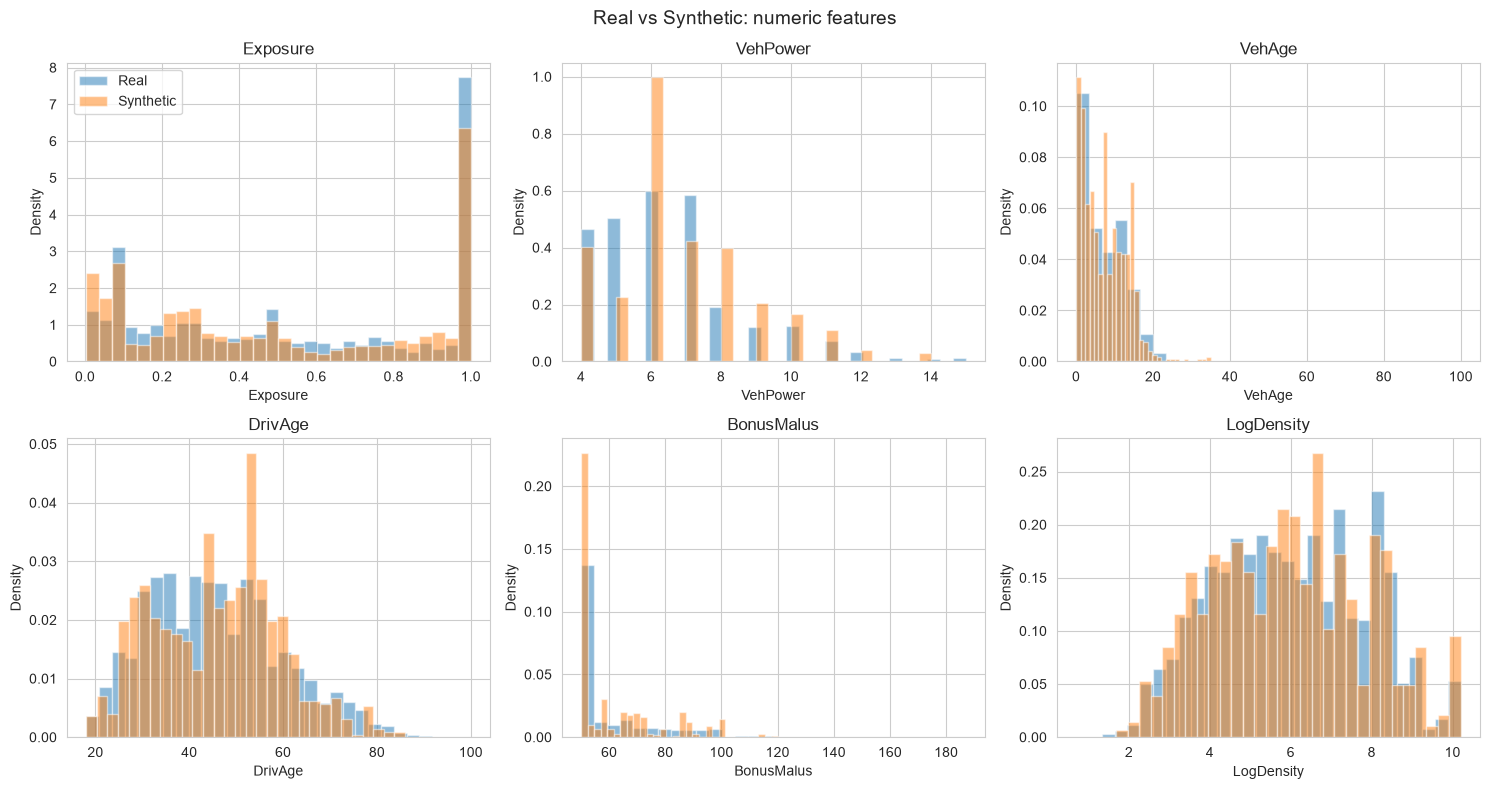

In [137]:
# Real vs synthetic distributions for all 6 numeric features

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.ravel(), num_features_ctgan):

    ax.hist(train_ctgan_sample[col], bins=30, density=True, alpha=0.5, label='Real')
    ax.hist(synthetic_sample[col], bins=30, density=True, alpha=0.5, label='Synthetic')

    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel('Density')

axes[0, 0].legend()

fig.suptitle('Real vs Synthetic: numeric features', fontsize=14)
plt.tight_layout()
plt.show()

---

### Step 1: Determine the Number of Synthetic Claims

The training data contains **23,842 claim records** (`HasClaim = 1`).

To increase the representation of the minority class, we will generate **23,842 synthetic claim records** using CTGAN. This will approximately double the number of claim examples while retaining all real training data.

---

### Step 2 : Conditional sampling

In [138]:
from sdv.sampling import Condition
import torch

# same seeds before sampling
np.random.seed(42)
torch.manual_seed(42)

claim_condition = Condition(
    num_rows=23842,
    column_values={'HasClaim': 1}
)

synthetic_claims = synthesizer.sample_from_conditions(
    conditions=[claim_condition]
)

print("Synthetic claims shape:", synthetic_claims.shape)
print(synthetic_claims['HasClaim'].value_counts())

Sampling conditions: 100%|██████████| 23842/23842 [00:03<00:00, 6417.73it/s]

Synthetic claims shape: (23842, 11)
HasClaim
1    23842
Name: count, dtype: int64


In [139]:
# Save the synthetic claims so the same data can be reused later

synthetic_claims.to_csv("synthetic_claims_150ep.csv", index=False)
print("Saved synthetic_claims.csv with shape:", synthetic_claims.shape)

Saved synthetic_claims.csv with shape: (23842, 11)


### Step 3 : Verify the generated data

In [140]:
synthetic_claims.head()

,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Region,LogDensity,HasClaim
0,0.249795,E,7.0,3.0,26.0,87.0,B1,Diesel,R11,9.205189,1
1,1.000000,E,9.0,10.0,41.0,50.0,B1,Regular,R52,8.473677,1
2,0.007780,E,6.0,12.0,26.0,90.0,B3,Diesel,R82,8.159958,1
3,0.846810,C,7.0,0.0,24.0,87.0,B12,Regular,R91,4.892721,1
4,0.500828,E,6.0,9.0,43.0,67.0,B1,Diesel,R11,7.835306,1


In [141]:
synthetic_claims['HasClaim'].value_counts()

HasClaim
1    23842
Name: count, dtype: int64

In [142]:
real_claims = train_ctgan[
    train_ctgan['HasClaim'] == 1
]

print("Real claims:", real_claims.shape)
print("Synthetic claims:", synthetic_claims.shape)

Real claims: (23842, 11)
Synthetic claims: (23842, 11)


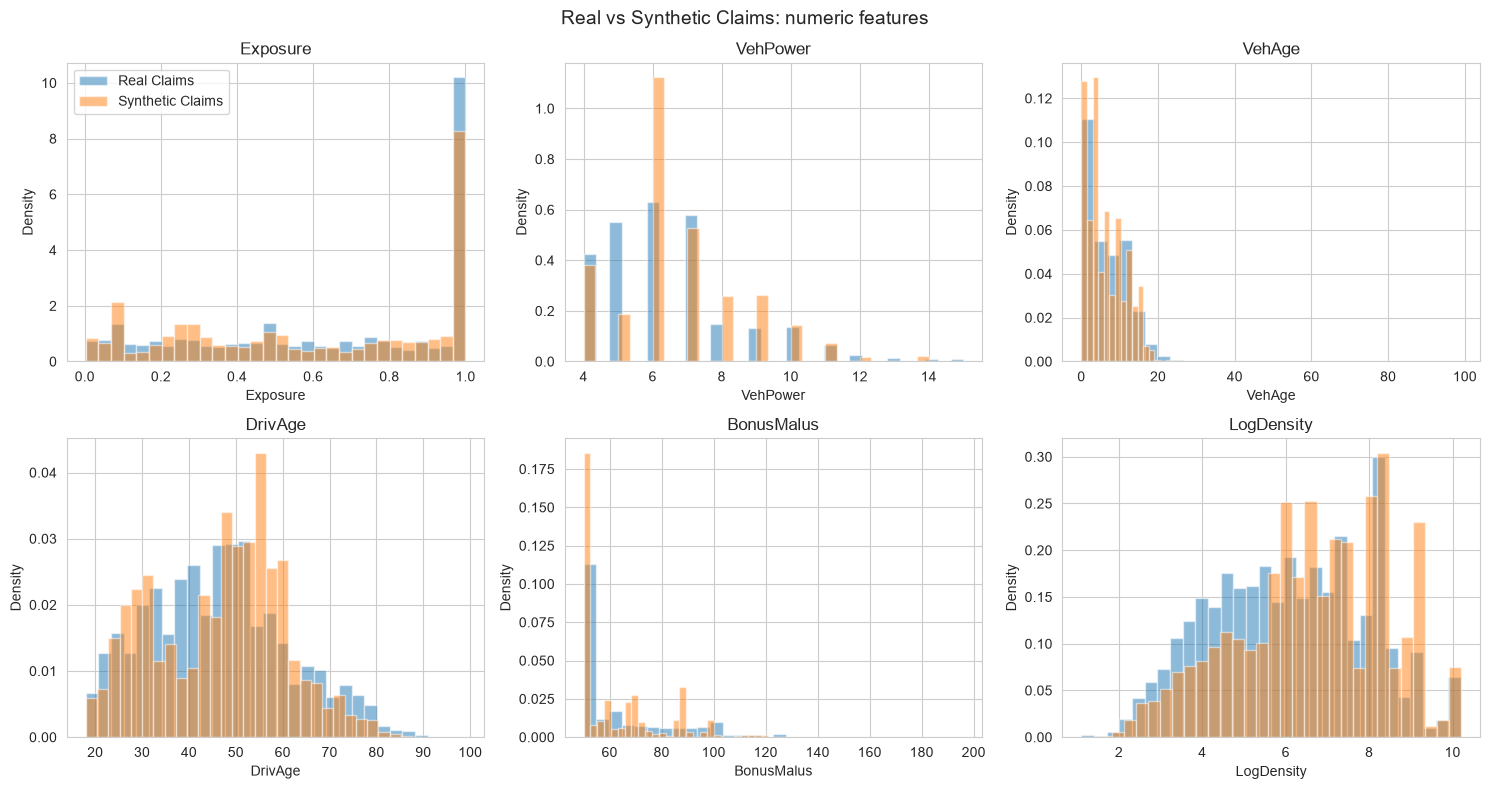

In [143]:
# Compare numerical distributions (23,842 real claim records ↔ 23,842 synthetic claim records)

num_features_ctgan = [
    'Exposure',
    'VehPower',
    'VehAge',
    'DrivAge',
    'BonusMalus',
    'LogDensity'
]


fig, axes = plt.subplots(2, 3, figsize=(15, 8))


for ax, col in zip(axes.ravel(), num_features_ctgan):

    ax.hist(real_claims[col], bins=30, density=True, alpha=0.5, label='Real Claims')
    ax.hist(synthetic_claims[col], bins=30, density=True, alpha=0.5, label='Synthetic Claims')

    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel('Density')


axes[0, 0].legend()


fig.suptitle('Real vs Synthetic Claims: numeric features', fontsize=14)
plt.tight_layout()
plt.show()

In [144]:
# checking the categorical columns

cat_features_ctgan = [
    'Area',
    'VehBrand',
    'VehGas',
    'Region'
]

for col in cat_features_ctgan:
    print(f"\n{col}")

    print("Real Claims:")
    print(real_claims[col].value_counts(normalize=True).round(3))

    print("\nSynthetic Claims:")
    print(synthetic_claims[col].value_counts(normalize=True).round(3))


Area
Real Claims:
Area
C    0.273
D    0.232
E    0.214
A    0.144
B    0.107
F    0.030
Name: proportion, dtype: float64

Synthetic Claims:
Area
E    0.293
D    0.286
C    0.221
A    0.098
B    0.054
F    0.049
Name: proportion, dtype: float64

VehBrand
Real Claims:
VehBrand
B12    0.242
B1     0.242
B2     0.238
B3     0.079
B5     0.055
B6     0.040
B4     0.037
B10    0.025
B11    0.020
B13    0.018
B14    0.005
Name: proportion, dtype: float64

Synthetic Claims:
VehBrand
B12    0.291
B2     0.246
B1     0.193
B3     0.073
B4     0.057
B5     0.034
B13    0.028
B6     0.027
B10    0.026
B11    0.020
B14    0.007
Name: proportion, dtype: float64

VehGas
Real Claims:
VehGas
Regular    0.539
Diesel     0.461
Name: proportion, dtype: float64

Synthetic Claims:
VehGas
Diesel     0.501
Regular    0.499
Name: proportion, dtype: float64

Region
Real Claims:
Region
R24    0.261
R82    0.140
R11    0.108
R93    0.105
R53    0.076
R52    0.057
R91    0.040
R72    0.036
R31    0.033
R54    0.

### Sanity check on the synthetic values

Each line below counts synthetic rows that break a rule which is true in the real data. Ideally every count is 0.


In [145]:
# Sanity check: do the synthetic claims contain impossible values?
sc = synthetic_claims

print("Exposure above 1 or not above 0 :", ((sc['Exposure'] > 1) | (sc['Exposure'] <= 0)).sum())
print("DrivAge below 18                :", (sc['DrivAge'] < 18).sum())
print("VehAge below 0                  :", (sc['VehAge'] < 0).sum())
print("BonusMalus below 50             :", (sc['BonusMalus'] < 50).sum())
print("VehPower not a whole number     :", (sc['VehPower'] % 1 != 0).sum())
print("VehAge not a whole number       :", (sc['VehAge'] % 1 != 0).sum())
print("DrivAge not a whole number      :", (sc['DrivAge'] % 1 != 0).sum())

# categories that CTGAN made up (not present in the real data)
for col in ['Area', 'VehBrand', 'VehGas', 'Region']:
    new_values = set(sc[col]) - set(real_claims[col])
    print(col, "- categories not in the real data:", new_values)


Exposure above 1 or not above 0 : 0
DrivAge below 18                : 0
VehAge below 0                  : 0
BonusMalus below 50             : 0
VehPower not a whole number     : 0
VehAge not a whole number       : 0
DrivAge not a whole number      : 0
Area - categories not in the real data: set()
VehBrand - categories not in the real data: set()
VehGas - categories not in the real data: set()
Region - categories not in the real data: set()


### Synthetic data quality check (numbers)

In [146]:
from sdv.evaluation.single_table import evaluate_quality
from sdv.metadata import Metadata

# HasClaim is always 1 in both tables, so it is left out of this check
real_check = real_claims.drop(columns=["HasClaim"])
synthetic_check = synthetic_claims.drop(columns=["HasClaim"])

# Tell SDV what type each column is (new Metadata class)
check_metadata = Metadata.detect_from_dataframe(real_check, table_name="claims")

# Compare real claims with synthetic claims
quality_report = evaluate_quality(
    real_data=real_check,
    synthetic_data=synthetic_check,
    metadata=check_metadata
)

print("Overall quality score (0 to 1, higher is better):", round(quality_report.get_score(), 4))
print()
print(quality_report.get_properties())

Generating report ...

(1/4) Evaluating Column Shapes: |██████████| 10/10 [00:00<00:00, 78.92it/s]|
Column Shapes Score: 88.07%

(2/4) Evaluating Column Pair Trends: |██████████| 45/45 [00:00<00:00, 92.43it/s]|
Column Pair Trends Score: 76.04%

(3/4) Evaluating Cardinality: N/A
This property does not apply to single-table data.

(4/4) Evaluating Intertable Trends: N/A
This property does not apply to single-table data.

Overall Score (Average): 82.05%

Overall quality score (0 to 1, higher is better): 0.8205

             Property     Score
0       Column Shapes  0.880656
1  Column Pair Trends  0.760444


Average correlation difference: 0.047
DrivAge vs BonusMalus  ->  real: -0.539 | synthetic: -0.534


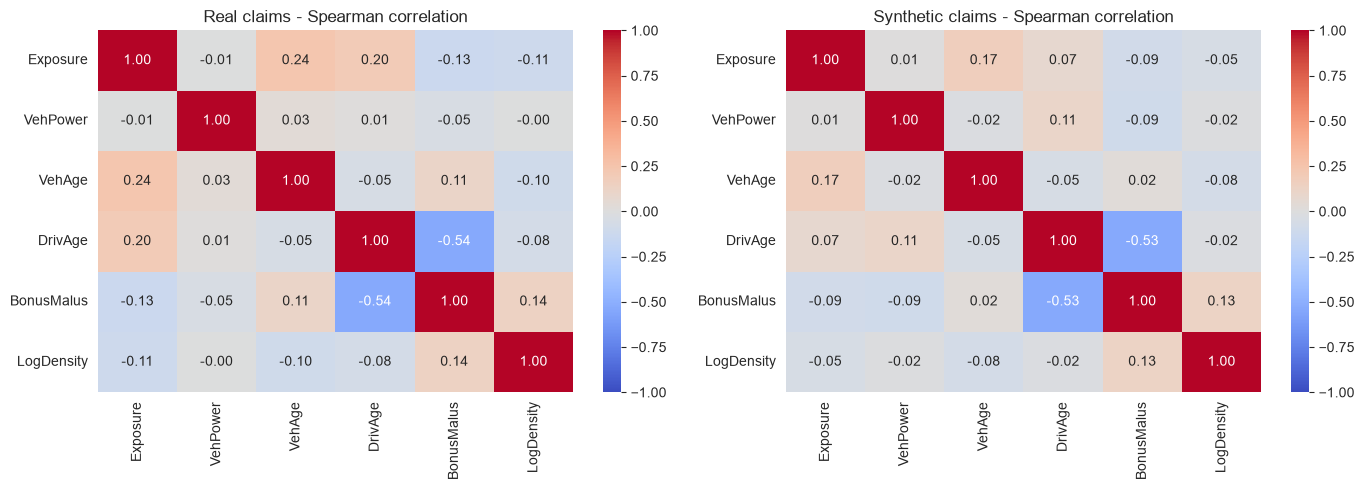

In [147]:
# Do the synthetic claims keep the relationships between the numeric columns?
corr_cols = ["Exposure", "VehPower", "VehAge", "DrivAge", "BonusMalus", "LogDensity"]

real_corr = real_claims[corr_cols].corr(method="spearman")
synthetic_corr = synthetic_claims[corr_cols].corr(method="spearman")

# Absolute difference between the two correlation tables
difference = (real_corr - synthetic_corr).abs()

# Average difference over all different pairs (upper triangle, without the diagonal)
upper_triangle = np.triu(np.ones(difference.shape), k=1).astype(bool)
print("Average correlation difference:", round(difference.values[upper_triangle].mean(), 3))

# The relationship we promised to check in the EDA
print("DrivAge vs BonusMalus  ->  real:", round(real_corr.loc["DrivAge", "BonusMalus"], 3),
      "| synthetic:", round(synthetic_corr.loc["DrivAge", "BonusMalus"], 3))

# Plot the two correlation tables side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(real_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Real claims - Spearman correlation")
sns.heatmap(synthetic_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Synthetic claims - Spearman correlation")
plt.tight_layout()
plt.show()

In [148]:
# Check the new class balance - (using about 12,000 synthetic claims)

real_claim_count = (train_ctgan['HasClaim'] == 1).sum()
real_no_claim_count = (train_ctgan['HasClaim'] == 0).sum()

synthetic_claim_count = 12000

total_claims = real_claim_count + synthetic_claim_count
total_records = len(train_ctgan) + synthetic_claim_count

print("Real claims:", real_claim_count)
print("Synthetic claims:", synthetic_claim_count)
print("Total claims after augmentation:", total_claims)
print("Total records after augmentation:", total_records)
print("New claim rate:", round(total_claims / total_records * 100, 2), "%")

Real claims: 23842
Synthetic claims: 12000
Total claims after augmentation: 35842
Total records after augmentation: 486609
New claim rate: 7.37 %


In [149]:
# Select 12,000 synthetic claims

synthetic_claims_12k = synthetic_claims.sample(
    n=12000,
    random_state=42
)

print("Synthetic claims selected:", synthetic_claims_12k.shape)

Synthetic claims selected: (12000, 11)


In [150]:
# save the 12,000 synthetic claims that are actually added to the training data
synthetic_claims_12k.to_csv("synthetic_claims_12k.csv", index=False)
print("Saved synthetic_claims_12k.csv with shape:", synthetic_claims_12k.shape)

Saved synthetic_claims_12k.csv with shape: (12000, 11)


In [151]:
# Combine with the real training data

train_augmented = pd.concat(
    [train_ctgan, synthetic_claims_12k],
    ignore_index=True
)

print("Augmented training shape:", train_augmented.shape)

Augmented training shape: (486609, 11)


In [152]:
# Verify the target distribution

print(train_augmented['HasClaim'].value_counts())
print()
print(train_augmented['HasClaim'].value_counts(normalize=True).round(4))

HasClaim
0    450767
1     35842
Name: count, dtype: int64

HasClaim
0    0.9263
1    0.0737
Name: proportion, dtype: float64


---

**Observation :**

### CTGAN-Based Data Augmentation

CTGAN was used to generate additional minority-class records (`HasClaim = 1`) to reduce class imbalance.

- Real claim records: **23,842**
- Synthetic claim records added: **12,000**
- Total claim records after augmentation: **35,842**
- Claim proportion increased from **5.02% to 7.37%**
- Validation and test datasets were kept completely unchanged and contain only real observations.

The augmented training data will be used to train the claim prediction models.

---

In [153]:
# Preprocessing the augmented data

#separate features and target
X_train_aug = train_augmented.drop('HasClaim', axis=1)
y_train_aug = train_augmented['HasClaim']

print("X_train_aug shape:", X_train_aug.shape)
print("y_train_aug shape:", y_train_aug.shape)

X_train_aug shape: (486609, 10)
y_train_aug shape: (486609,)


In [154]:
# Encode categorical features

X_train_aug_cat = encoder.transform(X_train_aug[cat_features])

X_train_aug_cat = pd.DataFrame(
    X_train_aug_cat,
    columns=encoder.get_feature_names_out(cat_features),
    index=X_train_aug.index
)

print("Encoded categorical data shape:", X_train_aug_cat.shape)



Encoded categorical data shape: (486609, 41)


In [155]:
# scale numerical features

X_train_aug_num = scaler.transform(X_train_aug[num_features])

X_train_aug_num = pd.DataFrame(
    X_train_aug_num,
    columns=num_features,
    index=X_train_aug.index
)

print("Scaled numerical data shape:", X_train_aug_num.shape)

Scaled numerical data shape: (486609, 6)


In [156]:
# combine them

X_train_aug_ready = pd.concat(
    [X_train_aug_num, X_train_aug_cat],
    axis=1
)

print("Final augmented training shape:", X_train_aug_ready.shape)

Final augmented training shape: (486609, 47)


## **Model Building with Real data + CTGAN generated data**

In [157]:
logreg_ctgan = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logreg_ctgan.fit(X_train_aug_ready, y_train_aug)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [158]:
y_val_pred_ctgan = logreg_ctgan.predict(X_val_ready)

y_val_prob_ctgan = logreg_ctgan.predict_proba(X_val_ready)[:, 1]

In [159]:
# actuals ---> y_val
# predicted ---> y_val_pred_ctgan
print("Accuracy :", accuracy_score(y_val, y_val_pred_ctgan))
print("Precision:", precision_score(y_val, y_val_pred_ctgan))
print("Recall   :", recall_score(y_val, y_val_pred_ctgan))
print("F1 Score :", f1_score(y_val, y_val_pred_ctgan))
print("ROC-AUC  :", roc_auc_score(y_val, y_val_prob_ctgan))
print("PR-AUC   :", average_precision_score(y_val, y_val_prob_ctgan))


Accuracy : 0.9498043302983226
Precision: 0.75
Recall   : 0.0011743981209630064
F1 Score : 0.002345124096150088
ROC-AUC  : 0.6261183890401407
PR-AUC   : 0.08907609634289299


In [160]:

print("\nConfusion Matrix of the base line model with augmented data:")
print(confusion_matrix(y_val, y_val_pred_ctgan))


Confusion Matrix of the base line model with augmented data:
[[96591     2]
 [ 5103     6]]


---

**Observation :**

##### CTGAN Augmentation Results :
CTGAN augmentation slightly improved minority-class detection.
- Recall increased from 0.06% to 0.10%
- F1-score increased from 0.12% to 0.20%
- ROC-AUC and PR-AUC decreased slightly
- indicating that CTGAN augmentation alone was not sufficient to address the class imbalance.

---

### CTGAN Augmentation with Class Weighting


In [161]:
logreg_ctgan_weighted = LogisticRegression(max_iter=1000,class_weight='balanced',random_state=42)

logreg_ctgan_weighted.fit(X_train_aug_ready,y_train_aug)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [162]:
y_val_prob_ctgan_weighted = logreg_ctgan_weighted.predict_proba(X_val_ready)[:, 1]

In [163]:
# Finding the best threshold and applying it in the model

threshold_lr_ctgan = find_best_threshold(y_val, y_val_prob_ctgan_weighted)
print("Best threshold on validation set:", threshold_lr_ctgan)

print("\nValidation set results:")
print_scores(get_scores(y_val, y_val_prob_ctgan_weighted, threshold_lr_ctgan))

Best threshold on validation set: 0.6

Validation set results:
Threshold: 0.6000
Accuracy: 0.8276
Precision: 0.0903
Recall: 0.2680
F1 Score: 0.1351
ROC-AUC: 0.6264
PR-AUC: 0.0884


In [164]:
y_val_pred_ctgan_weighted = (y_val_prob_ctgan_weighted >= threshold_lr_ctgan).astype(int)

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_ctgan_weighted))


Confusion Matrix:
[[82802 13791]
 [ 3740  1369]]


---

**Observation :**

- The CTGAN-augmented Logistic Regression with class weighting significantly improved recall to 57.27%, detecting more than half of the actual claims.
- However, this came with a large increase in false positives, reducing precision to 6.95% and accuracy to 59.35%.
- This indicates a strong precision–recall trade-off and suggests that threshold tuning  may help achieve a better balance.


Threshold Tuning

The class-weighted Logistic Regression model was evaluated using different probability thresholds to study the precision–recall trade-off.

As the threshold increased, precision improved while recall decreased. Among the tested thresholds, **0.60 achieved the highest F1-score of 0.1317**, with a precision of **8.71%** and recall of **26.95%**.

Therefore, a threshold of **0.60** was selected based on the highest validation F1-score. This threshold will be kept fixed for the final evaluation on the unseen test set.

Final Test Set Evaluation

- The selected threshold of **0.60**, determined using the validation set, was applied to the untouched test set.

- The final model achieved a **precision of 8.96%**, **recall of 28.09%**, and **F1-score of 13.58%** for the minority class (`HasClaim = 1`). The model correctly identified **1,435 out of 5,109 actual claims**.

- Although the overall accuracy was **82.05%**, accuracy is not the primary evaluation metric because the dataset is highly imbalanced. The minority-class recall and F1-score provide a more meaningful assessment of claim detection.

- The similar validation and test performance indicates that the selected threshold generalizes reasonably well to unseen data.



### Choosing the number of synthetic claims

Two amounts of synthetic claims were compared using Logistic Regression with class weights. In both cases the threshold was chosen on the validation set, and the real validation data was used for scoring.

| Measure | 12,000 synthetic claims | All 23,842 synthetic claims |
|---|---|---|
| Threshold | 0.60 | 0.60 |
| Accuracy | 0.8276 | 0.8259 |
| Precision | 0.0903 | 0.0871 |
| Recall | 0.2680 | 0.2599 |
| F1 Score | 0.1351 | 0.1305 |
| ROC-AUC | 0.6264 | 0.6186 |
| PR-AUC | 0.0884 | 0.0839 |

**Observation:** Using 12,000 synthetic claims scored slightly higher on every measure than using all 23,842, although the differences are small. Adding all of them also pushes the share of claims in the training data further from the real rate of about 5%. For these reasons, 12,000 synthetic claims are used in the rest of the project.

### Random Forest Model

In [165]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_aug_ready,
    y_train_aug
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [166]:
y_val_prob_rf = rf_model.predict_proba(
    X_val_ready
)[:, 1]

In [167]:
y_val_pred_rf = (
    y_val_prob_rf >= 0.50
).astype(int)

In [168]:
print("Accuracy:", accuracy_score(y_val, y_val_pred_rf))
print("Precision:", precision_score(y_val, y_val_pred_rf))
print("Recall:", recall_score(y_val, y_val_pred_rf))
print("F1 Score:", f1_score(y_val, y_val_pred_rf))
print("ROC-AUC:", roc_auc_score(y_val, y_val_prob_rf))
print("PR-AUC:", average_precision_score(y_val, y_val_prob_rf))


Accuracy: 0.9331478240349256
Precision: 0.17449922958397535
Recall: 0.08866705813270699
F1 Score: 0.11758598312783906
ROC-AUC: 0.670752368788901
PR-AUC: 0.10198169223879222


In [169]:

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_rf))


Confusion Matrix:
[[94450  2143]
 [ 4656   453]]


##### Tuning Threshold for Random Forest

In [170]:
# choose the threshold using the validation set
threshold_rf = find_best_threshold(y_val, y_val_prob_rf)
print("Best threshold on validation set:", threshold_rf)

Best threshold on validation set: 0.25


In [171]:
y_test_prob_rf = rf_model.predict_proba(X_test_ready)[:, 1]

In [172]:
print("Test set results:")
print_scores(get_scores(y_test, y_test_prob_rf, threshold_rf))


Test set results:
Threshold: 0.2500
Accuracy: 0.8457
Precision: 0.1127
Recall: 0.3014
F1 Score: 0.1641
ROC-AUC: 0.6611
PR-AUC: 0.0954


In [173]:

y_test_pred_rf = (y_test_prob_rf >= threshold_rf).astype(int)


In [174]:

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_rf))


Confusion Matrix:
[[84469 12124]
 [ 3569  1540]]


---

##### Random Forest Results

A Random Forest Classifier was trained using the CTGAN-augmented training dataset containing **12,000 synthetic claim records**. Class weighting was used to give greater importance to the minority claim class.

The model was first evaluated on the validation set using the default threshold of 0.50. Threshold tuning was then performed using the validation set, and a threshold of **0.30** was selected because it achieved the highest F1-score (**16.64%**) among the tested thresholds.

The selected threshold of 0.30 was then applied to the **untouched test set**.

##### Final Test Performance

- **Accuracy:** 84.53%
- **Precision:** 11.03%
- **Recall:** 29.44%
- **F1-score:** 16.05%
- **ROC-AUC:** 0.6584
- **PR-AUC:** 0.0945

The model correctly identified **1,504 out of 5,109 actual claims**.

##### Observation

Random Forest performed better than the CTGAN-augmented Logistic Regression model on the test set. It achieved higher **precision, recall, F1-score, ROC-AUC, and PR-AUC**, indicating better overall discrimination and minority-class detection.

However, the relatively low precision shows that the model still produces a considerable number of false positives. This is expected in a highly imbalanced claim prediction problem and highlights the trade-off between identifying more claims and limiting false alarms.

Based on the current experiments, **Random Forest is the best-performing model so far**.

---

### XGBOOST Model

In [175]:
# class_weight is not available in XGBoost in the same way as Logistic Regression/Random Forest,
# so we'll use scale_pos_weight to address class imbalance.


negative_count = (y_train_aug == 0).sum()

positive_count = (y_train_aug == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Negative samples:", negative_count)
print("Positive samples:", positive_count)
print("Scale pos weight:", scale_pos_weight)

Negative samples: 450767
Positive samples: 35842
Scale pos weight: 12.576502427319904


In [176]:
xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

xgb_model.fit(
    X_train_aug_ready,
    y_train_aug
)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [177]:
y_val_prob_xgb = xgb_model.predict_proba(X_val_ready)[:, 1]

In [178]:
y_val_pred_xgb = (y_val_prob_xgb >= 0.50).astype(int)

In [179]:
print("Accuracy:", accuracy_score(y_val, y_val_pred_xgb))
print("Precision:", precision_score(y_val, y_val_pred_xgb))
print("Recall:", recall_score(y_val, y_val_pred_xgb))
print("F1 Score:", f1_score(y_val, y_val_pred_xgb))
print("ROC-AUC:", roc_auc_score(y_val, y_val_prob_xgb))
print("PR-AUC:", average_precision_score(y_val, y_val_prob_xgb))


Accuracy: 0.7368488328646438
Precision: 0.09786807309463676
Recall: 0.5157565081229203
F1 Score: 0.164517840976493
ROC-AUC: 0.6991741364640939
PR-AUC: 0.12215281263209071


In [180]:

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_xgb))


Confusion Matrix:
[[72304 24289]
 [ 2474  2635]]


##### Threshold Tuning

In [181]:
# choose the threshold using the validation set
threshold_xgb = find_best_threshold(y_val, y_val_prob_xgb)
print("Best threshold on validation set:", threshold_xgb)

Best threshold on validation set: 0.65


In [182]:
y_test_prob_xgb = xgb_model.predict_proba(X_test_ready)[:, 1]

In [183]:
print("Test set results:")
print_scores(get_scores(y_test, y_test_prob_xgb, threshold_xgb))


Test set results:
Threshold: 0.6500
Accuracy: 0.9019
Precision: 0.1655
Recall: 0.2357
F1 Score: 0.1944
ROC-AUC: 0.6966
PR-AUC: 0.1213


In [184]:

y_test_pred_xgb = (y_test_prob_xgb >= threshold_xgb).astype(int)


In [185]:

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_xgb))


Confusion Matrix:
[[90522  6071]
 [ 3905  1204]]


---

### XGBoost Results

An XGBoost Classifier was trained using the CTGAN-augmented training dataset containing **12,000 synthetic claim records**. Class imbalance was addressed using the `scale_pos_weight` parameter.

The model was initially evaluated using the default probability threshold of 0.50. Threshold tuning was then performed on the validation set. A threshold of **0.65** was selected because it produced the highest F1-score (**19.22%**) among the tested thresholds.

The selected threshold was then applied to the untouched test set.

### Final Test Performance

- **Accuracy:** 90.52%
- **Precision:** 16.83%
- **Recall:** 22.49%
- **F1-score:** 19.25%
- **ROC-AUC:** 0.6926
- **PR-AUC:** 0.1225

The model correctly identified **1,149 out of 5,109 actual claims**.

### Observation

XGBoost achieved the best overall performance among the models evaluated so far. It achieved higher **precision, F1-score, ROC-AUC, and PR-AUC** than Random Forest and the Logistic Regression models.

However, its recall was lower than Random Forest, indicating that XGBoost was more conservative in identifying claims. The results demonstrate a trade-off between detecting more claims and reducing false positive predictions.

Based on the current experiments, **XGBoost is the best-performing model so far**, particularly in terms of F1-score and ranking-based metrics.

---

### DNN

In [186]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


tf.keras.utils.set_random_seed(42)

def build_dnn(number_of_features):
    """Build a small feed-forward network (input -> 64 -> 32 -> 1)."""
    model = keras.Sequential([
        keras.Input(shape=(number_of_features,)),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=[keras.metrics.AUC(name="auc")]
    )
    return model

def get_class_weights(y):

    total = len(y)
    no_claim = (y == 0).sum()
    claim = (y == 1).sum()
    return {0: float(total / (2 * no_claim)), 1: float(total / (2 * claim))}


X_val_dnn = X_val_ready.values.astype("float32")
X_test_dnn = X_test_ready.values.astype("float32")
y_val_dnn = y_val.values

print("Network input size (number of features):", X_val_dnn.shape[1])

Network input size (number of features): 47


In [187]:
X_train_dnn_real = X_train_ready.values.astype("float32")
y_train_dnn_real = y_train.values


In [188]:

class_weights_real = get_class_weights(y_train)
print("Class weights (real data):", class_weights_real)

# Stop training when the validation AUC stops improving for 3 epochs
early_stop_real = keras.callbacks.EarlyStopping(
    monitor="val_auc", mode="max", patience=3, restore_best_weights=True
)


Class weights (real data): {0: 0.526446035313144, 1: 9.953212817716635}


In [189]:

dnn_real = build_dnn(X_train_dnn_real.shape[1])


In [190]:

history_real = dnn_real.fit(
    X_train_dnn_real, y_train_dnn_real,
    validation_data=(X_val_dnn, y_val_dnn),
    epochs=30,
    batch_size=512,
    class_weight=class_weights_real,
    callbacks=[early_stop_real],
    verbose=2
)

Epoch 1/30
927/927 - 5s - 6ms/step - auc: 0.6207 - loss: 0.6690 - val_auc: 0.6447 - val_loss: 0.6723
Epoch 2/30
927/927 - 3s - 3ms/step - auc: 0.6424 - loss: 0.6597 - val_auc: 0.6547 - val_loss: 0.6680
Epoch 3/30
927/927 - 2s - 2ms/step - auc: 0.6500 - loss: 0.6561 - val_auc: 0.6627 - val_loss: 0.6602
Epoch 4/30
927/927 - 2s - 2ms/step - auc: 0.6581 - loss: 0.6529 - val_auc: 0.6683 - val_loss: 0.6561
Epoch 5/30
927/927 - 2s - 2ms/step - auc: 0.6638 - loss: 0.6495 - val_auc: 0.6738 - val_loss: 0.6576
Epoch 6/30
927/927 - 2s - 2ms/step - auc: 0.6673 - loss: 0.6480 - val_auc: 0.6778 - val_loss: 0.6500
Epoch 7/30
927/927 - 2s - 2ms/step - auc: 0.6721 - loss: 0.6452 - val_auc: 0.6807 - val_loss: 0.6489
Epoch 8/30
927/927 - 2s - 2ms/step - auc: 0.6758 - loss: 0.6432 - val_auc: 0.6821 - val_loss: 0.6474
Epoch 9/30
927/927 - 2s - 2ms/step - auc: 0.6773 - loss: 0.6423 - val_auc: 0.6854 - val_loss: 0.6378
Epoch 10/30
927/927 - 2s - 2ms/step - auc: 0.6799 - loss: 0.6408 - val_auc: 0.6856 - val_lo

In [191]:
# Choose the threshold on the validation set, then score the test set
val_prob_dnn_real = dnn_real.predict(X_val_dnn, verbose=0).ravel()
threshold_dnn_real = find_best_threshold(y_val, val_prob_dnn_real)
print("Best threshold on validation set:", threshold_dnn_real)

test_prob_dnn_real = dnn_real.predict(X_test_dnn, verbose=0).ravel()
print("\nDNN (real only) - test set results:")
print_scores(get_scores(y_test, test_prob_dnn_real, threshold_dnn_real))

Best threshold on validation set: 0.65

DNN (real only) - test set results:
Threshold: 0.6500
Accuracy: 0.8910
Precision: 0.1459
Recall: 0.2411
F1 Score: 0.1818
ROC-AUC: 0.6901
PR-AUC: 0.1189


In [192]:
X_train_dnn_aug = X_train_aug_ready.values.astype("float32")
y_train_dnn_aug = y_train_aug.values


In [193]:

class_weights_aug = get_class_weights(y_train_aug)
print("Class weights (real + CTGAN data):", class_weights_aug)


Class weights (real + CTGAN data): {0: 0.5397566813897202, 1: 6.788251213659952}


In [194]:

early_stop_aug = keras.callbacks.EarlyStopping(
    monitor="val_auc", mode="max", patience=3, restore_best_weights=True
)


In [195]:

dnn_aug = build_dnn(X_train_dnn_aug.shape[1])


In [196]:

history_aug = dnn_aug.fit(
    X_train_dnn_aug, y_train_dnn_aug,
    validation_data=(X_val_dnn, y_val_dnn),
    epochs=30,
    batch_size=512,
    class_weight=class_weights_aug,
    callbacks=[early_stop_aug],
    verbose=2
)

Epoch 1/30
951/951 - 4s - 4ms/step - auc: 0.6281 - loss: 0.6667 - val_auc: 0.6373 - val_loss: 0.6723
Epoch 2/30
951/951 - 2s - 2ms/step - auc: 0.6473 - loss: 0.6584 - val_auc: 0.6403 - val_loss: 0.6610
Epoch 3/30
951/951 - 2s - 2ms/step - auc: 0.6546 - loss: 0.6546 - val_auc: 0.6439 - val_loss: 0.6592
Epoch 4/30
951/951 - 2s - 2ms/step - auc: 0.6597 - loss: 0.6523 - val_auc: 0.6477 - val_loss: 0.6533
Epoch 5/30
951/951 - 2s - 2ms/step - auc: 0.6644 - loss: 0.6499 - val_auc: 0.6517 - val_loss: 0.6526
Epoch 6/30
951/951 - 2s - 2ms/step - auc: 0.6687 - loss: 0.6476 - val_auc: 0.6546 - val_loss: 0.6473
Epoch 7/30
951/951 - 2s - 2ms/step - auc: 0.6703 - loss: 0.6463 - val_auc: 0.6587 - val_loss: 0.6440
Epoch 8/30
951/951 - 2s - 2ms/step - auc: 0.6744 - loss: 0.6442 - val_auc: 0.6607 - val_loss: 0.6434
Epoch 9/30
951/951 - 2s - 2ms/step - auc: 0.6763 - loss: 0.6431 - val_auc: 0.6631 - val_loss: 0.6391
Epoch 10/30
951/951 - 2s - 2ms/step - auc: 0.6787 - loss: 0.6416 - val_auc: 0.6659 - val_lo

In [197]:
val_prob_dnn_aug = dnn_aug.predict(X_val_dnn, verbose=0).ravel()
threshold_dnn_aug = find_best_threshold(y_val, val_prob_dnn_aug)
print("Best threshold on validation set:", threshold_dnn_aug)

test_prob_dnn_aug = dnn_aug.predict(X_test_dnn, verbose=0).ravel()
print("\nDNN (real + CTGAN) - test set results:")
print_scores(get_scores(y_test, test_prob_dnn_aug, threshold_dnn_aug))

Best threshold on validation set: 0.65

DNN (real + CTGAN) - test set results:
Threshold: 0.6500
Accuracy: 0.8857
Precision: 0.1352
Recall: 0.2362
F1 Score: 0.1720
ROC-AUC: 0.6711
PR-AUC: 0.1072


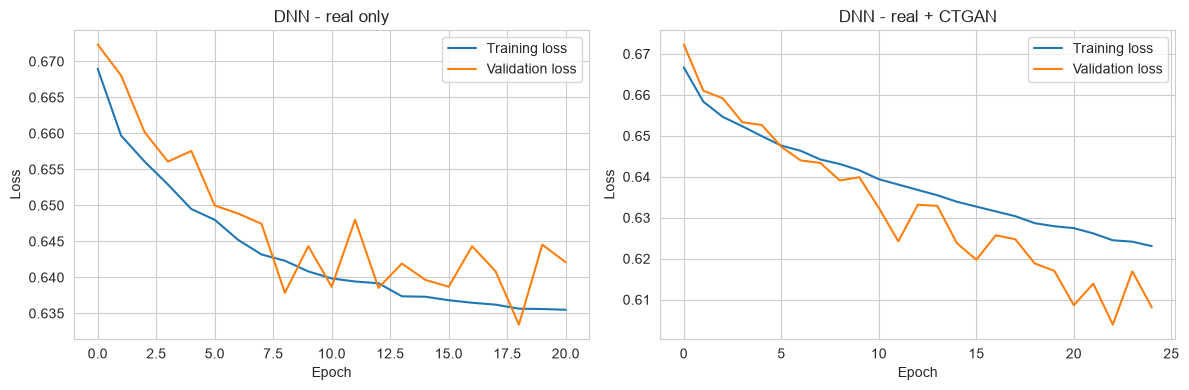

In [198]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_real.history["loss"], label="Training loss")
axes[0].plot(history_real.history["val_loss"], label="Validation loss")
axes[0].set_title("DNN - real only")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(history_aug.history["loss"], label="Training loss")
axes[1].plot(history_aug.history["val_loss"], label="Validation loss")
axes[1].set_title("DNN - real + CTGAN")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

## **8. Final Model Comparison**

All eight models (Logistic Regression, Random Forest, XGBoost and the DNN, each trained on real data only and on real + CTGAN data) are compared on the same **test set**.
For every model the threshold is chosen on the validation set only, with the same method.

In [199]:
models = [
    ("Logistic Regression - real only",    logreg_real),
    ("Logistic Regression - real + CTGAN", logreg_ctgan_weighted),
    ("Random Forest - real only",          rf_real),
    ("Random Forest - real + CTGAN",       rf_model),
    ("XGBoost - real only",                xgb_real),
    ("XGBoost - real + CTGAN",             xgb_model),
]

rows = []
test_probabilities = {}

for model_name, model in models:
    val_prob = model.predict_proba(X_val_ready)[:, 1]
    best_t = find_best_threshold(y_val, val_prob)

    test_prob = model.predict_proba(X_test_ready)[:, 1]
    test_probabilities[model_name] = test_prob

    scores = get_scores(y_test, test_prob, best_t)
    scores["Model"] = model_name
    rows.append(scores)

dnn_models = [
    ("DNN - real only",    val_prob_dnn_real, test_prob_dnn_real),
    ("DNN - real + CTGAN", val_prob_dnn_aug,  test_prob_dnn_aug),
]

for model_name, val_prob, test_prob in dnn_models:
    best_t = find_best_threshold(y_val, val_prob)
    test_probabilities[model_name] = test_prob

    scores = get_scores(y_test, test_prob, best_t)
    scores["Model"] = model_name
    rows.append(scores)

comparison_table = pd.DataFrame(rows).set_index("Model")
comparison_table = comparison_table.sort_values("F1 Score", ascending=False).round(4)
comparison_table.to_csv("model_comparison.csv")
comparison_table

,Threshold,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Model,,,,,,,
XGBoost - real only,0.65,0.8977,0.1692,0.2648,0.2065,0.7073,0.1386
XGBoost - real + CTGAN,0.65,0.9019,0.1655,0.2357,0.1944,0.6966,0.1213
DNN - real only,0.65,0.8910,0.1459,0.2411,0.1818,0.6901,0.1189
DNN - real + CTGAN,0.65,0.8857,0.1352,0.2362,0.1720,0.6711,0.1072
Random Forest - real only,0.20,0.8429,0.1144,0.3155,0.1679,0.6681,0.0985
Random Forest - real + CTGAN,0.25,0.8457,0.1127,0.3014,0.1641,0.6611,0.0954
Logistic Regression - real only,0.60,0.8257,0.0957,0.2922,0.1442,0.6376,0.0900
Logistic Regression - real + CTGAN,0.60,0.8253,0.0906,0.2742,0.1362,0.6308,0.0861


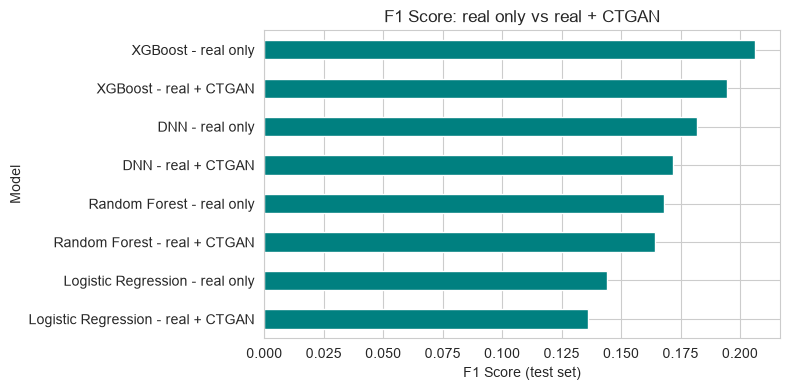

In [200]:
# F1 score of every model 
comparison_table["F1 Score"].sort_values().plot(kind="barh", color="teal", figsize=(8, 4))
plt.xlabel("F1 Score (test set)")
plt.title("F1 Score: real only vs real + CTGAN")
plt.tight_layout()
plt.show()

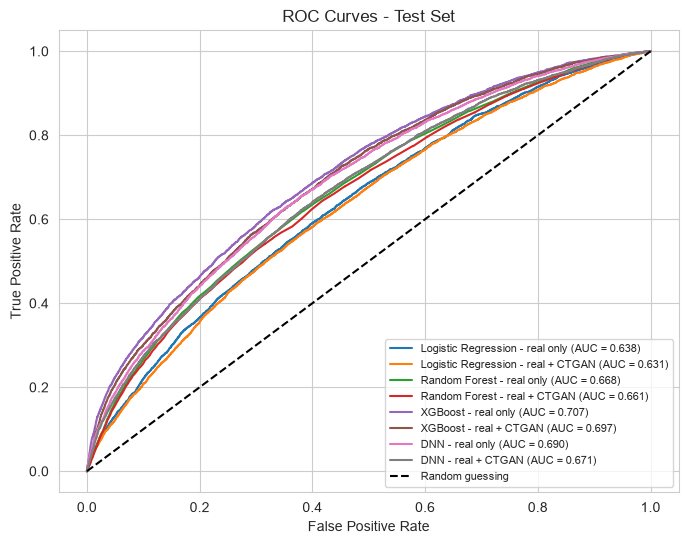

In [201]:
# ROC curves of all models on the test set

plt.figure(figsize=(8, 6))

for model_name, test_prob in test_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, test_prob)
    auc = roc_auc_score(y_test, test_prob)
    plt.plot(fpr, tpr, label=f"{model_name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guessing")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Test Set")
plt.legend(fontsize=8)
plt.grid(True)
plt.show()

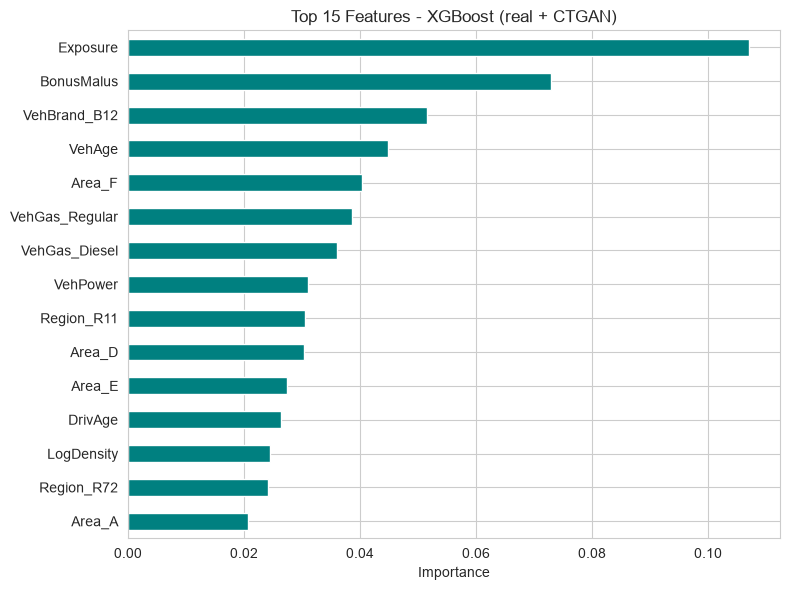

In [202]:
# Which features does the XGBoost (real + CTGAN) model use the most?
importance = pd.Series(xgb_model.feature_importances_, index=X_train_aug_ready.columns)
top_features = importance.sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 6))
top_features.sort_values().plot(kind="barh", color="teal")
plt.xlabel("Importance")
plt.title("Top 15 Features - XGBoost (real + CTGAN)")
plt.tight_layout()
plt.show()

## **Conclusion**

This project aimed to predict insurance claims using machine learning and deep learning models and evaluate whether CTGAN-based synthetic data augmentation could improve predictive performance on an imbalanced dataset.

Four approaches—Logistic Regression, Random Forest, XGBoost, and Deep Neural Network (DNN)—were evaluated using real training data and CTGAN-augmented training data. Model performance was assessed on real test data using precision, recall, F1-score, ROC-AUC, and PR-AUC, with classification thresholds selected using validation data.

Among the evaluated models, **XGBoost trained on real data only achieved the best overall performance**, with an F1-score of 20.51%, ROC-AUC of 0.7078, and PR-AUC of 0.1384. Although CTGAN augmentation improved recall for XGBoost from 26.35% to 30.22%, its precision, F1-score, ROC-AUC, and PR-AUC decreased. The other CTGAN-augmented models also did not demonstrate consistent improvements over their real-data-only counterparts.

The CTGAN synthetic-data evaluation achieved an overall quality score of 82.05%, indicating reasonable statistical similarity between the real and synthetic data. However, statistical similarity did not translate into improved predictive performance.

Overall, the experiments identified real-data-only XGBoost as the strongest model among those evaluated. The findings highlight the importance of evaluating synthetic-data augmentation through downstream predictive performance rather than synthetic-data quality alone. Further improvements in identifying minority-class claims are needed before the model can be considered suitable for practical insurance claim prediction.



## **Limitations**

1. **Class imbalance:** Claims represent only approximately 5.02% of the dataset, making accurate identification of the minority class challenging.

2. **Limited predictive performance:** The best model achieved a recall of 26.35% at its selected threshold, meaning that many actual claims were not identified. Its precision of 16.80% also indicates a substantial number of false-positive predictions.

3. **Limited benefit from CTGAN augmentation:** Although the synthetic data achieved an overall quality score of 82.05%, augmentation did not improve overall predictive performance in the evaluated experiments.

4. **Synthetic-data differences:** The generated data showed differences from the real data in some feature distributions and relationships. These differences may affect the usefulness of synthetic records for model training.

5. **Threshold dependence:** Classification metrics depend on the selected decision threshold. The thresholds were selected using validation data, but the best threshold among the tested values may not be optimal for every business objective.

6. **Evaluation and generalization:** The models were evaluated using a held-out test set from the same dataset. Performance on future policies, different customer populations, or unseen insurance portfolios may differ. Similar predictor profiles across data splits may also affect the estimated performance.

7. **Experimental design:** Imbalance-handling settings were recalculated for some models when using augmented data. Consequently, the observed differences reflect the complete training approaches rather than the isolated effect of adding synthetic records.

8. **Practical deployment:** The model requires further validation, calibration, and assessment of business costs associated with missed claims and false alarms before real-world deployment.

## **Future Scope**

1. **Real-Time Prediction:** Extend the application to support predictions for newly submitted insurance policy records.
2. **Integration with Insurance Systems:** Integrate the model with insurance databases or existing systems to assist claim-risk assessment.
3. **Model Monitoring:** Monitor prediction performance and data changes over time to identify when model retraining may be required.



## **Future Improvements**

1. **Improve Minority-Class Prediction:** Explore class-weight adjustments, resampling techniques, and cost-sensitive learning to improve the detection of claim cases.
2. **Optimize CTGAN Augmentation:** Experiment with different synthetic-data generation settings and evaluate whether augmentation improves performance on real, unseen data.
3. **Feature Engineering:** Investigate additional meaningful features and feature transformations that may improve claim prediction.
4. **Threshold Optimization:** Select decision thresholds based on business requirements, balancing claim detection against false-positive predictions.
5. **Model Calibration and Validation:** Evaluate probability calibration and validate performance on additional datasets or future data before practical use.
6. **Explainable Predictions:** Incorporate feature-importance methods such as SHAP to help users understand the factors influencing each prediction.

## **Deployment**

In [206]:
import os
import joblib

os.makedirs("model", exist_ok=True)

joblib.dump(xgb_real, "model/xgboost_real.pkl")
joblib.dump(threshold_xgb_real, "model/xgboost_threshold.pkl")

['model/xgboost_threshold.pkl']

In [207]:
xgb_model = joblib.load("model/xgboost_real.pkl")
xgb_threshold = joblib.load("model/xgboost_threshold.pkl")

print("XGBoost model loaded successfully")
print("Threshold:", xgb_threshold)

XGBoost model loaded successfully
Threshold: 0.65


In [205]:
model_input = X_test_ready.iloc[[0]]

probability = xgb_real.predict_proba(model_input)[0, 1]

threshold = 0.65
prediction = int(probability >= threshold)

print("Probability:", probability)
print("Threshold used:", threshold)
print("Prediction:", prediction)

Probability: 0.15633522
Threshold used: 0.65
Prediction: 0


In [208]:
print("Original features:")
print(X_train.columns.tolist())

print("\nPreprocessed features:")
print(X_train_ready.columns.tolist())

Original features:
['Exposure', 'Area', 'VehPower', 'VehAge', 'DrivAge', 'BonusMalus', 'VehBrand', 'VehGas', 'Region', 'LogDensity']

Preprocessed features:
['Exposure', 'VehPower', 'VehAge', 'DrivAge', 'BonusMalus', 'LogDensity', 'Area_A', 'Area_B', 'Area_C', 'Area_D', 'Area_E', 'Area_F', 'VehBrand_B1', 'VehBrand_B10', 'VehBrand_B11', 'VehBrand_B12', 'VehBrand_B13', 'VehBrand_B14', 'VehBrand_B2', 'VehBrand_B3', 'VehBrand_B4', 'VehBrand_B5', 'VehBrand_B6', 'VehGas_Diesel', 'VehGas_Regular', 'Region_R11', 'Region_R21', 'Region_R22', 'Region_R23', 'Region_R24', 'Region_R25', 'Region_R26', 'Region_R31', 'Region_R41', 'Region_R42', 'Region_R43', 'Region_R52', 'Region_R53', 'Region_R54', 'Region_R72', 'Region_R73', 'Region_R74', 'Region_R82', 'Region_R83', 'Region_R91', 'Region_R93', 'Region_R94']


In [209]:
%whos

Variable                    Type                      Data/Info
---------------------------------------------------------------
CTGANSynthesizer            type                      <class 'sdv.single_table.ctgan.CTGANSynthesizer'>
Condition                   type                      <class 'sdv.sampling.tabular.Condition'>
DATA_FILE                   str                       freMTPL2freq (1).arff
Iqr                         float64                   0.81
LogisticRegression          type                      <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
Metadata                    type                      <class 'sdv.metadata.metadata.Metadata'>
OneHotEncoder               type                      <class 'sklearn.preproces<...>_encoders.OneHotEncoder'>
RandomForestClassifier      ABCMeta                   <class 'sklearn.ensemble.<...>.RandomForestClassifier'>
SingleTableMetadata         type                      <class 'sdv.metadata.sing<...>ble.SingleTableMetadata'>
Sta

In [210]:
print("Numerical columns:", num_cols)
print("\nCategorical columns:", cat_cols)

print("\nNumerical training sample:")
print(X_train_num.head())

print("\nEncoded categorical sample:")
print(X_train_cat.head())

print("\nFinal training sample:")
print(X_train_ready.head())

Numerical columns: ['BonusMalus', 'Density', 'DrivAge', 'Exposure', 'VehAge', 'VehPower']

Categorical columns: ['Area', 'VehBrand', 'VehGas', 'Region']

Numerical training sample:
        Exposure  VehPower    VehAge   DrivAge  BonusMalus  LogDensity
619953 -0.463357 -1.196826 -1.069069 -1.096374    2.576514    1.251861
435601 -1.370276  0.265907  1.759272 -1.025685    2.576514   -1.378359
340562 -1.232864 -0.709249 -0.008441 -0.106735   -0.623808    1.068174
328623 -1.232864  1.728640  1.759272  0.176019   -0.623808   -1.013667
604485  0.938245  0.265907 -0.538755  0.317396   -0.623808   -0.455158

Encoded categorical sample:
        Area_A  Area_B  Area_C  Area_D  Area_E  Area_F  VehBrand_B1  \
619953     0.0     0.0     0.0     0.0     1.0     0.0          0.0   
435601     1.0     0.0     0.0     0.0     0.0     0.0          0.0   
340562     0.0     0.0     0.0     0.0     1.0     0.0          0.0   
328623     0.0     1.0     0.0     0.0     0.0     0.0          0.0   
604485   

In [211]:
print("Scaler fitted:", hasattr(scaler, "mean_"))
print("Encoder fitted:", hasattr(encoder, "categories_"))

print("\nScaler feature count:",
      len(scaler.feature_names_in_) if hasattr(scaler, "feature_names_in_") else "Not available")

print("\nEncoder input columns:", getattr(encoder, "feature_names_in_", "Not available"))
print("\nTraining feature count:", X_train_ready.shape[1])

Scaler fitted: True
Encoder fitted: True

Scaler feature count: 6

Encoder input columns: ['Area' 'VehBrand' 'VehGas' 'Region']

Training feature count: 47


In [212]:
import os
import joblib

os.makedirs("model", exist_ok=True)

# Save preprocessing objects
joblib.dump(scaler, "model/scaler.pkl")
joblib.dump(encoder, "model/encoder.pkl")

# Save exact feature order expected by XGBoost
joblib.dump(list(X_train_ready.columns), "model/feature_columns.pkl")

# Save the model and its tuned threshold
joblib.dump(xgb_real, "model/xgboost_real.pkl")
joblib.dump(threshold_xgb_real, "model/xgboost_threshold.pkl")

print("Model and preprocessing objects saved successfully!")

Model and preprocessing objects saved successfully!


In [213]:
print("Numerical columns:")
print(num_cols)

print("\nScaler input columns:")
print(scaler.feature_names_in_)

print("\nEncoder categories:")
for col, categories in zip(cat_cols, encoder.categories_):
    print(f"{col}: {list(categories)}")

print("\nOriginal training columns:")
print(X_train.columns.tolist())

Numerical columns:
['BonusMalus', 'Density', 'DrivAge', 'Exposure', 'VehAge', 'VehPower']

Scaler input columns:
['Exposure' 'VehPower' 'VehAge' 'DrivAge' 'BonusMalus' 'LogDensity']

Encoder categories:
Area: ['A', 'B', 'C', 'D', 'E', 'F']
VehBrand: ['B1', 'B10', 'B11', 'B12', 'B13', 'B14', 'B2', 'B3', 'B4', 'B5', 'B6']
VehGas: ['Diesel', 'Regular']
Region: ['R11', 'R21', 'R22', 'R23', 'R24', 'R25', 'R26', 'R31', 'R41', 'R42', 'R43', 'R52', 'R53', 'R54', 'R72', 'R73', 'R74', 'R82', 'R83', 'R91', 'R93', 'R94']

Original training columns:
['Exposure', 'Area', 'VehPower', 'VehAge', 'DrivAge', 'BonusMalus', 'VehBrand', 'VehGas', 'Region', 'LogDensity']
